# SC4002: joint BiLSTM — evaluator v2

**Read run status from the final completion cell and `run_artifacts/completion.json`.**
This template requires fresh training; it does not supply default-model v2
performance results. This revision uses exact typed character-span occurrences
and the same verified original MASSIVE English data
as `NLP_Final_project.ipynb`. Earlier executed notebooks and results are archived
locally under `artifacts/evaluator_v2/prechange`; their text-set scores and selected
epochs are historical v1 observations, not results for this revision.

This standalone notebook embeds all required source. Edit only the labelled
configuration cell, save, then restart the kernel and run all cells. Defaults
train the selected BiLSTM settings for 20 epochs each. Development-only runs
support tuning; final runs reload, freeze and test chosen settings. No rebuild
or manual hash edit is needed for supported settings. Use a fresh execution
directory, the tested Python 3.12/CUDA environment and `main.ipynb` filename.
Launch Jupyter with `PYTHONHASHSEED=42` and
`CUBLAS_WORKSPACE_CONFIG=:4096:8`, then execute every cell in order.

The brief requires Stage 1 without generative AI; assistance actually occurred
at the user's request and no lecturer-approved exception is claimed. Group
details and verified human contributions remain pending. No old score is used
as a training target, and no historical checkpoint is loaded.


In [1]:
from __future__ import annotations
import os
from pathlib import Path
import sys
if os.environ.get('PYTHONHASHSEED') != '42':
    raise RuntimeError('Restart the kernel from Jupyter launched with PYTHONHASHSEED=42; setting it inside a running interpreter is insufficient.')
if os.environ.get('CUBLAS_WORKSPACE_CONFIG', ':4096:8') != ':4096:8':
    raise RuntimeError('Restart with CUBLAS_WORKSPACE_CONFIG=:4096:8.')
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'
NOTEBOOK_PATH = (Path.cwd() / 'main.ipynb').resolve()
if not NOTEBOOK_PATH.is_file():
    raise FileNotFoundError('Keep main.ipynb in the kernel working directory.')
RUN_ROOT = Path.cwd() / 'run_artifacts'
RUN_ROOT.mkdir(exist_ok=False)
os.environ['MPLCONFIGDIR'] = str(RUN_ROOT / 'matplotlib_cache')
print('Fresh execution directory:', Path.cwd())
print('Interpreter:', sys.executable)


Fresh execution directory: C:\Users\Admin\Desktop\SC4002
Interpreter: C:\Users\Admin\Desktop\SC4002\.venv\Scripts\python.exe


## Editable run configuration — change settings here

Edit literal dictionary values below, save, then Restart Kernel and Run All in
a fresh directory. All other implementation cells remain protected.
`evaluate_test=False` trains/selects/verifies on development only; `True` also
freezes and tests once per stage. Use test only after choosing hyperparameters.
`dataset_path=None` downloads original English data; a path string reuses a
verified local file, copying it into this run. AdamW and task weights 1.0 are
fixed; complete models must remain within 20M. Actual settings are recorded.

In [2]:
RUNTIME = {'device': 'auto',
 'seed': 42,
 'num_workers': 0,
 'deterministic_algorithms': True,
 'cudnn_deterministic': True,
 'cudnn_benchmark': False,
 'allow_tf32': False,
 'cublas_workspace_config': ':4096:8',
 'precision': 'float32'}

STAGE1_CONFIG = {'schema_version': 1,
 'stage': 'stage1',
 'model': {'embedding_dim': 256,
           'hidden_dim': 512,
           'num_layers': 1,
           'dropout': 0.3},
 'training': {'optimizer': 'AdamW',
              'learning_rate': 0.001,
              'weight_decay': 0.0001,
              'batch_size': 32,
              'max_epochs': 20,
              'intent_loss_weight': 1.0,
              'slot_loss_weight': 1.0,
              'gradient_clip_norm': 5.0}}

STAGE2_CONFIG = {'schema_version': 1,
 'stage': 'stage2',
 'model': {'embedding_dim': 256,
           'hidden_dim': 512,
           'num_layers': 1,
           'dropout': 0.3,
           'use_char': True,
           'char_embedding_dim': 32,
           'char_channels': 64,
           'char_kernel_size': 3,
           'use_crf': True,
           'intent_conditioning': True,
           'intent_context_dim': 64},
 'training': {'optimizer': 'AdamW',
              'learning_rate': 0.001,
              'weight_decay': 0.0001,
              'batch_size': 32,
              'max_epochs': 20,
              'intent_loss_weight': 1.0,
              'slot_loss_weight': 1.0,
              'gradient_clip_norm': 5.0}}

RUN_OPTIONS = {'evaluate_test': True,
 'dataset_path': None,
 'device': 'cuda',
 'verification_timeout_seconds': 300}


## Shared runtime and typed prediction contract

Seed 42 is reset before each model construction. Training uses FP32, deterministic algorithms, deterministic cuDNN, disabled TF32, and a persistent seeded data-loader generator with zero workers. Selection uses the unrounded arithmetic mean of development intent accuracy and slot micro F1; an exact tie retains the earlier epoch. Offsets are Python character positions and are retained for audit.

In [3]:
from __future__ import annotations

from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
import random
from typing import Any

def relative_project_path(root: Path, value: str) -> Path:
    """Resolve a configured relative path and reject escape from the project."""
    path = Path(value)
    if path.anchor or not value.strip():
        raise ValueError(f'Expected a nonempty project-relative path: {value!r}')
    resolved = (root / path).resolve()
    if not resolved.is_relative_to(root.resolve()):
        raise ValueError(f'Configured path escapes the project: {value!r}')
    return resolved

def configure_reproducibility(runtime: dict[str, Any]) -> None:
    """Apply the documented seed/determinism policy before CUDA initialization."""
    expected = runtime['cublas_workspace_config']
    previous = os.environ.get('CUBLAS_WORKSPACE_CONFIG')
    if previous is not None and previous != expected:
        raise RuntimeError('Conflicting CUBLAS_WORKSPACE_CONFIG; restart with the protocol setting')
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = expected
    import numpy as np
    import torch
    seed = runtime['seed']
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(runtime['deterministic_algorithms'], warn_only=False)
    torch.backends.cudnn.deterministic = runtime['cudnn_deterministic']
    torch.backends.cudnn.benchmark = runtime['cudnn_benchmark']
    torch.backends.cuda.matmul.allow_tf32 = runtime['allow_tf32']
    torch.backends.cudnn.allow_tf32 = runtime['allow_tf32']

def select_device(requested: str='auto') -> Any:
    import torch
    if requested not in {'auto', 'cuda', 'cpu'}:
        raise ValueError('Device must be auto, cuda, or cpu')
    available = torch.cuda.is_available()
    if requested == 'cuda' and (not available):
        raise RuntimeError('CUDA was requested but is unavailable')
    return torch.device('cuda' if requested == 'cuda' or (requested == 'auto' and available) else 'cpu')

def dataloader_generator(seed: int) -> Any:
    """Use with num_workers=0 in the initial experiment protocol."""
    import torch
    return torch.Generator().manual_seed(seed)

def selection_score(intent_accuracy: float, slot_micro_f1: float) -> float:
    """Mean of unrounded fractional dev metrics, not displayed percentages."""
    values = (intent_accuracy, slot_micro_f1)
    if any((isinstance(value, bool) or not math.isfinite(value) or (not 0 <= value <= 1) for value in values)):
        raise ValueError('Selection metrics must be finite fractions in [0, 1]')
    return (intent_accuracy + slot_micro_f1) / 2

def is_improvement(candidate: float, best: float | None) -> bool:
    """Exact ties retain the earlier checkpoint; reload tolerance is unrelated."""
    for value in (candidate,) if best is None else (candidate, best):
        if isinstance(value, bool) or not math.isfinite(value) or (not 0 <= value <= 1):
            raise ValueError('Checkpoint scores must be finite fractions in [0, 1]')
    return best is None or candidate > best

def configuration_hash(configuration: dict[str, Any]) -> str:
    encoded = json.dumps(configuration, sort_keys=True, separators=(',', ':'), allow_nan=False).encode()
    return hashlib.sha256(encoded).hexdigest()


In [4]:
from __future__ import annotations
def project_root(explicit_root=None):
    if explicit_root is None:
        raise ValueError('Pass the notebook execution root explicitly.')
    return Path(explicit_root).expanduser().resolve()


In [5]:
from __future__ import annotations

"""Shared typed prediction format; offsets are Python character offsets in utt."""
from dataclasses import asdict, dataclass, field
from typing import Any

@dataclass(frozen=True)
class SlotSpan:
    slot_type: str
    text: str
    start: int
    end: int

    def __post_init__(self) -> None:
        if not isinstance(self.slot_type, str) or not self.slot_type:
            raise ValueError('Slot type must be a nonempty string')
        if not isinstance(self.text, str) or not self.text:
            raise ValueError('Slot span text must be a nonempty string')
        if type(self.start) is not int or type(self.end) is not int:
            raise ValueError('Slot offsets must be integers')
        if self.start < 0 or self.end <= self.start or self.end - self.start != len(self.text):
            raise ValueError('Slot offsets must describe the exact nonempty surface text')

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)

@dataclass(frozen=True)
class IntentSlotPrediction:
    record_id: str
    intent: str
    slots: tuple[SlotSpan, ...]
    utt: str | None = field(default=None, compare=False, repr=False)

    def __post_init__(self) -> None:
        if not isinstance(self.record_id, str) or not self.record_id:
            raise ValueError('Prediction record ID must be a nonempty string')
        if not isinstance(self.intent, str) or not self.intent:
            raise ValueError('Prediction intent must be a nonempty string')
        object.__setattr__(self, 'slots', tuple(self.slots))
        if any((not isinstance(slot, SlotSpan) for slot in self.slots)):
            raise ValueError('Prediction slots must contain SlotSpan values')
        if self.utt is not None:
            if not isinstance(self.utt, str):
                raise ValueError('Utterance sidecar must be a string')
            if any((self.utt[slot.start:slot.end] != slot.text for slot in self.slots)):
                raise ValueError('Slot must match its exact original utterance slice')

    def to_dict(self) -> dict[str, Any]:
        result = {'record_id': self.record_id, 'intent': self.intent, 'slots': [slot.to_dict() for slot in self.slots]}
        if self.utt is not None:
            result['utt'] = self.utt
        return result

    @classmethod
    def from_dict(cls, record: dict[str, Any]) -> IntentSlotPrediction:
        return cls(record_id=record['record_id'], intent=record['intent'], slots=tuple((SlotSpan(**slot) for slot in record['slots'])), utt=record.get('utt'))


In [6]:
"""Tokenizer-independent scoring and pinned MASSIVE data shared by both notebooks.

This module intentionally uses only the Python standard library so its exact
source can be embedded in a standalone submission notebook. Scores are fractions.
Character offsets refer to the original Python Unicode string, with exclusive
ends. The recorded data digest pins the project's original release bytes; it is
not an independently published authenticity certificate.
"""

import hashlib
import json
import os
from pathlib import Path
import re
import tarfile
import tempfile
from urllib.request import Request, urlopen


EVALUATOR_VERSION = "exact_character_span_v2"
DATASET_SHA256 = "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e"
EXPECTED_COUNTS = {"train": 11514, "dev": 2033, "test": 2974}
SOURCE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
ENGLISH_MEMBER = "1.0/data/en-US.jsonl"
_CONTRACT_ANNOTATION = re.compile(r"\[([A-Za-z_][A-Za-z_0-9]*)[ \t]*:[ \t]*(.*?)\]", re.DOTALL)
_CONTRACT_MAX_BYTES = 128 * 1024 * 1024


def _contract_json_hash(value):
    data = json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(data.encode("utf-8")).hexdigest()


def parse_annotated_spans(utt, annot_utt):
    """Strip annotation syntax only, requiring exact original-text reconstruction."""
    if not isinstance(utt, str) or not isinstance(annot_utt, str):
        raise TypeError("Utterance and annotated utterance must be strings")
    pieces, spans = [], []
    annotation_cursor = plain_cursor = 0
    for match in _CONTRACT_ANNOTATION.finditer(annot_utt):
        before = annot_utt[annotation_cursor:match.start()]
        pieces.append(before)
        plain_cursor += len(before)
        text = match.group(2)
        if not text:
            raise ValueError("An annotated slot cannot have empty text")
        spans.append({"slot_type": match.group(1), "text": text,
                      "start": plain_cursor, "end": plain_cursor + len(text)})
        pieces.append(text)
        plain_cursor += len(text)
        annotation_cursor = match.end()
    pieces.append(annot_utt[annotation_cursor:])
    if "".join(pieces) != utt:
        raise ValueError("Removing annotation syntax does not exactly reconstruct utt")
    return spans


def load_verified_massive(path):
    """Load only the pinned original bytes, preserving every partition and row."""
    path = Path(path)
    if path.is_symlink() or not path.is_file():
        raise ValueError("Dataset must be a regular, non-symlink file")
    if not 0 < path.stat().st_size <= _CONTRACT_MAX_BYTES:
        raise ValueError("Dataset size is outside the accepted range")
    raw = path.read_bytes()
    observed_hash = hashlib.sha256(raw).hexdigest()
    if observed_hash != DATASET_SHA256:
        raise ValueError("Dataset SHA256 differs from the pinned original release; refusing reuse")
    splits = {name: [] for name in EXPECTED_COUNTS}
    seen = set()
    for number, line in enumerate(raw.decode("utf-8").splitlines(), 1):
        if not line.strip():
            raise ValueError(f"Blank dataset row at line {number}")
        row = json.loads(line)
        if not isinstance(row, dict):
            raise ValueError(f"Dataset row {number} is not an object")
        for field in ("id", "utt", "intent", "annot_utt", "partition", "locale"):
            if not isinstance(row.get(field), str) or (field != "annot_utt" and not row[field]):
                raise ValueError(f"Invalid dataset field {field!r} at line {number}")
        if row["locale"] != "en-US" or row["partition"] not in splits:
            raise ValueError(f"Unexpected locale or partition at line {number}")
        if row["id"] in seen:
            raise ValueError(f"Duplicate dataset ID: {row['id']!r}")
        seen.add(row["id"])
        parse_annotated_spans(row["utt"], row["annot_utt"])
        splits[row["partition"]].append(row)
    counts = {name: len(rows) for name, rows in splits.items()}
    if counts != EXPECTED_COUNTS:
        raise ValueError(f"Original split counts differ: {counts!r}")
    manifest = {
        "evaluator_version": EVALUATOR_VERSION,
        "dataset_sha256": observed_hash,
        "source_url": SOURCE_URL,
        "archive_member": ENGLISH_MEMBER,
        "counts": counts,
        "split_id_sha256": {name: _contract_json_hash([row["id"] for row in rows])
                            for name, rows in splits.items()},
        "split_content_sha256": {name: _contract_json_hash(rows)
                                 for name, rows in splits.items()},
        "identity_scope": "Pinned original bytes; original row order and every record field retained",
    }
    return splits, manifest


def ensure_verified_massive(path):
    """Reuse verified data or safely stream its exact member from the official URL.

    Existing mismatched files are never overwritten. A verified temporary file
    is published using an exclusive atomic hard link; archive-controlled names
    are never used for filesystem writes and extract/extractall are not used.
    """
    path = Path(path)
    if path.exists() or path.is_symlink():
        return load_verified_massive(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    descriptor, temporary_name = tempfile.mkstemp(prefix=".massive-verified-", suffix=".part", dir=path.parent)
    temporary = Path(temporary_name)
    try:
        found = False
        with os.fdopen(descriptor, "wb") as output:
            request = Request(SOURCE_URL, headers={"User-Agent": "SC4002-verified-comparison/2"})
            with urlopen(request, timeout=60) as response, tarfile.open(fileobj=response, mode="r|gz") as archive:
                for member in archive:
                    if member.name != ENGLISH_MEMBER:
                        continue
                    if not member.isfile() or not 0 < member.size <= _CONTRACT_MAX_BYTES:
                        raise ValueError("English archive member must be a bounded regular file")
                    source = archive.extractfile(member)
                    if source is None:
                        raise ValueError("English archive member could not be read")
                    written = 0
                    with source:
                        for block in iter(lambda: source.read(1024 * 1024), b""):
                            written += len(block)
                            if written > member.size:
                                raise ValueError("English archive member exceeds its declared size")
                            output.write(block)
                    if written != member.size:
                        raise ValueError("English archive member is truncated")
                    found = True
                    break
            output.flush()
            os.fsync(output.fileno())
        if not found:
            raise ValueError("Official archive does not contain its exact English member")
        verified = load_verified_massive(temporary)
        try:
            os.link(temporary, path)
        except FileExistsError:
            return load_verified_massive(path)
        return verified
    finally:
        temporary.unlink(missing_ok=True)


def _contract_field(value, key):
    if isinstance(value, dict):
        if key not in value:
            raise ValueError(f"Missing required field: {key}")
        return value[key]
    try:
        return getattr(value, key)
    except AttributeError as error:
        raise ValueError(f"Missing required field: {key}") from error


def _contract_index(records, source):
    indexed = {}
    for record in records:
        record_id = _contract_field(record, "record_id")
        intent = _contract_field(record, "intent")
        if not isinstance(record_id, str) or not record_id or not isinstance(intent, str) or not intent:
            raise ValueError(f"{source} record ID and intent must be nonempty strings")
        if record_id in indexed:
            raise ValueError(f"Duplicate {source} record ID: {record_id!r}")
        indexed[record_id] = record
    return indexed


def _contract_span_keys(record, utt):
    keys = set()
    for span in _contract_field(record, "slots"):
        slot_type, text, start, end = (_contract_field(span, name)
                                     for name in ("slot_type", "text", "start", "end"))
        if not isinstance(slot_type, str) or not slot_type or not isinstance(text, str) or not text:
            raise ValueError("Slot type and text must be nonempty strings")
        if type(start) is not int or type(end) is not int or not 0 <= start < end or end - start != len(text):
            raise ValueError("Slot character offsets must describe its exact nonempty text")
        if utt is not None and (end > len(utt) or utt[start:end] != text):
            raise ValueError("Slot offsets and text do not match the original utterance")
        key = (slot_type, start, end, text)
        if key in keys:
            raise ValueError("Duplicate identical slot occurrence")
        keys.add(key)
    return keys


def score_exact_spans(gold, predictions):
    """Score typed objects or dictionaries with exact IDs and span occurrences.

    Gold dictionaries may include ``utt``. If supplied, both gold and predicted
    spans are checked against it. Without raw text, schema integrity, exact
    boundaries and literal text equality still apply to every matching key.
    """
    gold_by_id = _contract_index(gold, "gold")
    predicted_by_id = _contract_index(predictions, "prediction")
    if not gold_by_id:
        raise ValueError("Cannot evaluate an empty gold split")
    missing = gold_by_id.keys() - predicted_by_id.keys()
    unexpected = predicted_by_id.keys() - gold_by_id.keys()
    if missing or unexpected:
        raise ValueError(f"Prediction IDs do not match gold IDs: missing={sorted(missing)!r}, unexpected={sorted(unexpected)!r}")
    correct = tp = fp = fn = 0
    for record_id, reference in gold_by_id.items():
        predicted = predicted_by_id[record_id]
        utt = reference.get("utt") if isinstance(reference, dict) else getattr(reference, "utt", None)
        if utt is not None and not isinstance(utt, str):
            raise ValueError("Raw gold utterance must be a string")
        reference_keys = _contract_span_keys(reference, utt)
        predicted_keys = _contract_span_keys(predicted, utt)
        correct += int(_contract_field(reference, "intent") == _contract_field(predicted, "intent"))
        tp += len(reference_keys & predicted_keys)
        fp += len(predicted_keys - reference_keys)
        fn += len(reference_keys - predicted_keys)
    denominator = 2 * tp + fp + fn
    return {"intent_accuracy": correct / len(gold_by_id),
            "slot_micro_f1": 2 * tp / denominator if denominator else 0.0,
            "slot_tp": tp, "slot_fp": fp, "slot_fn": fn,
            "num_examples": len(gold_by_id), "correct_intents": correct}


def bio_to_character_spans(utt, token_offsets, tags):
    """Decode BIO into original character coordinates without tokenization bias.

    Offsets accept ``(start,end)`` pairs, dictionaries, or objects with start/end.
    Orphan/type-changing I starts a new span, consistently for both architectures.
    """
    if not isinstance(utt, str):
        raise TypeError("Utterance must be a string")
    token_offsets, tags = list(token_offsets), list(tags)
    if len(token_offsets) != len(tags):
        raise ValueError("BIO tag count must equal unpadded token count")
    offsets, previous_end = [], 0
    for offset in token_offsets:
        if isinstance(offset, (tuple, list)) and len(offset) == 2:
            start, end = offset
        else:
            start, end = _contract_field(offset, "start"), _contract_field(offset, "end")
        if type(start) is not int or type(end) is not int or not previous_end <= start < end <= len(utt):
            raise ValueError("Token offsets must be ordered, nonoverlapping character slices")
        offsets.append((start, end))
        previous_end = end
    spans = []
    active_type = None
    active_start = active_end = 0

    def close():
        nonlocal active_type
        if active_type is not None:
            spans.append({"slot_type": active_type, "text": utt[active_start:active_end],
                          "start": active_start, "end": active_end})
        active_type = None

    for (start, end), tag in zip(offsets, tags):
        if not isinstance(tag, str):
            raise ValueError("BIO tags must be strings")
        if tag == "O":
            close()
            continue
        if len(tag) < 3 or tag[:2] not in {"B-", "I-"} or not tag[2:]:
            raise ValueError(f"Invalid BIO tag: {tag!r}")
        slot_type = tag[2:]
        if tag.startswith("B-") or active_type != slot_type:
            close()
            active_type, active_start = slot_type, start
        active_end = end
    close()
    return spans


In [7]:
from __future__ import annotations

"""Visible notebook helpers for independent reload, reporting and error analysis.

The builder places these definitions inside the submitted notebook. There is no
runtime import from this file, the checkout, or historical experiment artifacts.
"""
import csv
import ast
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path
import subprocess
import sys
from IPython.display import Markdown, display

def nb_code_source(cell):
    value = cell.get('source', '')
    return value if isinstance(value, str) else ''.join(value)

def nb_notebook_configuration(notebook):
    """Allow literal settings edits only; keep every implementation cell protected."""
    cells = [cell for cell in notebook['cells'] if cell['cell_type'] == 'code']
    metadata = notebook['metadata']['phase7']
    expected = metadata['code_cell_sha256']
    indices = metadata.get('configuration_cell_indices', [])
    tagged = [i for i, cell in enumerate(cells) if 'configuration' in cell.get('metadata', {}).get('tags', [])]
    if indices != tagged or len(indices) != 1 or any((type(i) is not int for i in indices)):
        raise ValueError('Exactly one registered editable configuration cell is required')
    if len(expected) != len(cells):
        raise ValueError('Notebook cell count differs from its reviewed source manifest')
    values = {}
    for index, cell in enumerate(cells):
        text = nb_code_source(cell)
        if index not in indices:
            if hashlib.sha256(text.encode('utf-8')).hexdigest() != expected[index]:
                raise ValueError('Notebook implementation differs from its reviewed source manifest')
            continue
        for statement in ast.parse(text).body:
            if not isinstance(statement, ast.Assign) or len(statement.targets) != 1 or (not isinstance(statement.targets[0], ast.Name)):
                raise ValueError('Configuration must contain only literal dictionary assignments')
            name = statement.targets[0].id
            if name not in {'RUNTIME', 'STAGE1_CONFIG', 'STAGE2_CONFIG', 'RUN_OPTIONS'} or name in values:
                raise ValueError('Unexpected or duplicate configuration name: ' + name)
            try:
                values[name] = ast.literal_eval(statement.value)
            except (ValueError, TypeError) as error:
                raise ValueError('Use literal configuration values, not expressions or function calls') from error
            if not isinstance(values[name], dict):
                raise ValueError('Every configuration value must be a dictionary')
    if set(values) != {'RUNTIME', 'STAGE1_CONFIG', 'STAGE2_CONFIG', 'RUN_OPTIONS'}:
        raise ValueError('All four configuration dictionaries must be present')
    options = values['RUN_OPTIONS']
    if not {'evaluate_test', 'dataset_path', 'device'} <= set(options) or set(options) - {'evaluate_test', 'dataset_path', 'device', 'verification_timeout_seconds'} or type(options['evaluate_test']) is not bool:
        raise ValueError('RUN_OPTIONS must declare evaluate_test, dataset_path and device')
    if options['device'] not in {'cpu', 'cuda', 'auto'}:
        raise ValueError('Choose cpu, cuda or auto for device')
    if options['dataset_path'] is not None and (not isinstance(options['dataset_path'], str) or not options['dataset_path']):
        raise ValueError('dataset_path must be None or a nonempty path string')
    timeout = options.get('verification_timeout_seconds', 300)
    if timeout is not None and (type(timeout) is not int or timeout <= 0):
        raise ValueError('verification_timeout_seconds must be positive or None for no limit')
    return values

def nb_source_identity(notebook_path):
    notebook = json.loads(Path(notebook_path).read_text(encoding='utf-8'))
    nb_notebook_configuration(notebook)
    hashes = [hashlib.sha256(nb_code_source(cell).encode('utf-8')).hexdigest() for cell in notebook['cells'] if cell['cell_type'] == 'code']
    return hashlib.sha256(json.dumps(hashes, separators=(',', ':')).encode('ascii')).hexdigest()

def nb_capture_configuration(notebook_path, runtime, stage1, stage2, options, output):
    notebook = json.loads(Path(notebook_path).read_text(encoding='utf-8'))
    values = {'RUNTIME': runtime, 'STAGE1_CONFIG': stage1, 'STAGE2_CONFIG': stage2, 'RUN_OPTIONS': options}
    if nb_notebook_configuration(notebook) != values:
        raise ValueError('Save the edited notebook before restarting and running every cell')
    snapshot = {**values, 'code_sha256': nb_source_identity(notebook_path), 'configuration_sha256': hashlib.sha256(json.dumps(values, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode('utf-8')).hexdigest()}
    nb_support_write_json(output, snapshot)
    return snapshot

def nb_run_fresh_verifier(notebook_path, checkpoint, dataset_path, code_sha256, device, timeout=300):
    """Generate ordinary Python from visible definitions and run a new process."""
    notebook = json.loads(Path(notebook_path).read_text(encoding='utf-8'))
    assert nb_source_identity(notebook_path) == code_sha256
    definitions = [nb_code_source(cell) for cell in notebook['cells'] if cell['cell_type'] == 'code' and 'definitions' in cell.get('metadata', {}).get('tags', [])]
    source = 'from __future__ import annotations\n\n' + '\n\n'.join((text.replace('from __future__ import annotations\n', '') for text in definitions))
    driver = '\nif __name__ == "__main__":\n    checkpoint_path = Path(sys.argv[1]).resolve()\n    dataset_path = Path(sys.argv[2]).resolve()\n    code_identity, requested_device = sys.argv[3], sys.argv[4]\n    payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)\n    configure_reproducibility(payload["runtime"])\n    torch.set_default_dtype(torch.float32)\n    fresh_splits = load_massive(dataset_path)\n    fresh_mappings = fit_mappings(fresh_splits["train"])\n    if fresh_mappings.to_dict() != payload["mappings"]:\n        raise ValueError("Checkpoint mappings do not equal a fresh original-train-only fit")\n    fresh_dev = prepare_split(fresh_splits["dev"], fresh_mappings)\n    fresh_chars = payload.get("char_to_id", {})\n    if fresh_chars and fit_char_vocab(prepare_split(fresh_splits["train"], fresh_mappings)) != fresh_chars:\n        raise ValueError("Checkpoint character map differs from original training data")\n    report = nb_verify_development(checkpoint_path, fresh_dev, fresh_mappings,\n        fresh_chars, requested_device, file_sha256(dataset_path), code_identity,\n        fresh_python_process=True)\n    print(json.dumps(report, indent=2, allow_nan=False))\n'
    worker = Path(checkpoint).parent / 'fresh_development_verifier.py'
    worker.write_text(source + driver, encoding='utf-8')
    environment = os.environ.copy()
    environment.update(PYTHONHASHSEED='42', CUBLAS_WORKSPACE_CONFIG=':4096:8', PYTHONIOENCODING='utf-8')
    environment.pop('PYTHONPATH', None)
    result = subprocess.run([sys.executable, '-B', str(worker), str(Path(checkpoint).resolve()), str(Path(dataset_path).resolve()), code_sha256, str(device)], cwd=Path(checkpoint).parent, env=environment, capture_output=True, text=True, encoding='utf-8', timeout=timeout)
    (worker.parent / 'fresh_process_console.txt').write_text(result.stdout + result.stderr, encoding='utf-8')
    if result.returncode:
        raise RuntimeError('Fresh-process verification failed; see fresh_process_console.txt\n' + result.stderr[-2500:])
    report = json.loads((worker.parent / 'reload_check.json').read_text(encoding='utf-8'))
    if not report['passed'] or not report['fresh_python_process']:
        raise ValueError('A genuine fresh Python verification process is required')
    print('FRESH_PROCESS_DEVELOPMENT_VERIFIED', json.dumps(report, allow_nan=False))
    return report

def nb_support_write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + '\n', encoding='utf-8')

def nb_display_diagnosis(training, development, predictions, mappings, output_path):
    diagnosis = analyze_predictions(training, development, predictions, mappings)
    nb_support_write_json(output_path, diagnosis)
    columns = ('contains_oov', 'no_oov')
    lines = ['| Development group | Utterances | Intent accuracy | Slot micro F1 |', '| --- | ---: | ---: | ---: |']
    for name in columns:
        row = diagnosis['strata']['oov/' + name]
        lines.append(f'| {name} | {row['num_examples']} | {100 * row['intent_accuracy']:.2f}% | {100 * row['slot_micro_f1']:.2f}% |')
    display(Markdown('\n'.join(lines)))
    print('Development missed-slot categories:', diagnosis['false_negative_categories'])
    print('Development intent confusions:', diagnosis['intent_confusions'][:5])
    return diagnosis

def nb_build_result_table(stage1, stage2, output_root):
    rows, full_precision = ([], {})
    for label, summary in (('Stage-1 system', stage1), ('Stage-2 system', stage2)):
        full_precision[label] = {}
        for part in ('dev', 'test') if summary.get('test') is not None else ('dev',):
            metrics = summary[part]['metrics']
            full_precision[label][part] = metrics
            rows.append({'model_version': label, 'split': 'Validation' if part == 'dev' else 'Test', 'total_parameters': summary['parameter_counts']['total'], 'trainable_parameters': summary['parameter_counts']['trainable'], 'intent_accuracy_percent': f'{100 * metrics['intent_accuracy']:.2f}', 'slot_micro_f1_percent': f'{100 * metrics['slot_micro_f1']:.2f}', 'epochs_trained': summary['epochs_trained'], 'selected_epoch': summary['selected_epoch']})
    report = {'rows': rows, 'full_precision': full_precision, 'evaluator_version': EVALUATOR_VERSION, 'source': "This notebook's own checkpoint-reloaded final evaluations", 'stage2_minus_stage1_percentage_points': {part: {key: 100 * (stage2[part]['metrics'][key] - stage1[part]['metrics'][key]) for key in ('intent_accuracy', 'slot_micro_f1')} for part in (('dev', 'test') if stage1.get('test') is not None else ('dev',))}}
    output_root = Path(output_root)
    nb_support_write_json(output_root / 'results.json', report)
    with (output_root / 'results.csv').open('x', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    keys = list(rows[0])
    table = '| ' + ' | '.join(keys) + ' |\n| ' + ' | '.join(('---' for _ in keys)) + ' |\n'
    table += '\n'.join(('| ' + ' | '.join((str(row[key]) for key in keys)) + ' |' for row in rows))
    display(Markdown(table))
    print('UNROUNDED_METRIC_DELTAS', json.dumps(report['stage2_minus_stage1_percentage_points']))
    return report

def nb_show_error_cases(training, development, predictions, mappings, output_path):
    analysis = analyze_predictions(training, development, predictions, mappings)
    candidates = analysis['error_examples']
    chosen = []
    predicates = (lambda row: bool(row['oov_tokens']), lambda row: any((slot['category'] == 'same_type_wrong_boundary' for slot in row['false_negative_pairs'])), lambda row: row['gold_intent'] != row['predicted_intent'], lambda row: True)
    for predicate in predicates:
        for row in candidates:
            if predicate(row) and row['record_id'] not in {item['record_id'] for item in chosen}:
                chosen.append(dict(row))
                break
    if len(chosen) < 2:
        raise ValueError('At least two actual remaining errors are required for analysis')
    for row in chosen:
        hypotheses = []
        if row['oov_tokens']:
            hypotheses.append('Inference: unfamiliar words lack trained word-specific embeddings; character spelling features may not establish their entity meaning.')
        if any((slot['category'] == 'same_type_wrong_boundary' for slot in row['false_negative_pairs'])):
            hypotheses.append('Inference: the structured decoder still under- or over-extends this entity; valid BIO transitions do not guarantee the correct semantic boundary.')
        if row['gold_intent'] != row['predicted_intent']:
            hypotheses.append('Inference: short utterance/context ambiguity and limited examples for this phrasing may contribute; this example alone cannot establish a cause.')
        if not hypotheses:
            hypotheses.append('Inference: entity typing or omission remains difficult for this phrasing despite character and intent context features.')
        row['possible_causes_labelled_as_inferences'] = hypotheses
        row['possible_future_work'] = "Investigate targeted training-only support/error patterns and calibration with development data in a separate future study; do not tune using this run's test results."
        display(Markdown('**Actual remaining development error: record ' + row['record_id'] + '**\n\n```json\n' + json.dumps(row, ensure_ascii=False, indent=2) + '\n```'))
    report = {'source': 'New notebook Stage 2 saved development predictions', 'cases': chosen, 'total_remaining_error_utterances': analysis['utterances_with_any_error']}
    nb_support_write_json(output_path, report)
    return report


In [8]:
import platform
import torch
import numpy as np
from IPython.display import Image, Markdown, display
configuration_snapshot = nb_capture_configuration(NOTEBOOK_PATH, RUNTIME, STAGE1_CONFIG,
    STAGE2_CONFIG, RUN_OPTIONS, RUN_ROOT / 'run_configuration.json')
CODE_SHA256 = configuration_snapshot['code_sha256']
configure_reproducibility(RUNTIME)
torch.set_default_dtype(torch.float32)
DEVICE = select_device(RUN_OPTIONS['device'])
runtime_evidence = {'python': platform.python_version(), 'executable': sys.executable,
    'torch': str(torch.__version__), 'numpy': np.__version__, 'cuda_runtime': torch.version.cuda,
    'gpu': torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else None,
    'gpu_memory_bytes': torch.cuda.get_device_properties(DEVICE).total_memory if DEVICE.type == 'cuda' else None,
    'deterministic_algorithms': torch.are_deterministic_algorithms_enabled(),
    'settings': RUNTIME, 'implementation_sha256': CODE_SHA256,
    'execution_id': RUN_ROOT.parent.name, 'started_at_utc': datetime.now(timezone.utc).isoformat()}
nb_support_write_json(RUN_ROOT / 'runtime.json', runtime_evidence)
print('PHASE7_RUNTIME_JSON:', json.dumps(runtime_evidence, indent=2))


PHASE7_RUNTIME_JSON: {
  "python": "3.12.0",
  "executable": "C:\\Users\\Admin\\Desktop\\SC4002\\.venv\\Scripts\\python.exe",
  "torch": "2.7.1+cu126",
  "numpy": "1.26.4",
  "cuda_runtime": "12.6",
  "gpu": "NVIDIA GeForce RTX 3060 Ti",
  "gpu_memory_bytes": 8589410304,
  "deterministic_algorithms": true,
  "settings": {
    "device": "auto",
    "seed": 42,
    "num_workers": 0,
    "deterministic_algorithms": true,
    "cudnn_deterministic": true,
    "cudnn_benchmark": false,
    "allow_tf32": false,
    "cublas_workspace_config": ":4096:8",
    "precision": "float32"
  },
  "implementation_sha256": "59fa59f987aac1e48727550a5144b511e086611aec7f7fd65b752625c12f7c38",
  "execution_id": "SC4002",
  "started_at_utc": "2026-10-31T03:14:53.387799+00:00"
}


## Original data acquisition and preprocessing

The source below safely streams the official MASSIVE 1.0 archive and extracts exactly `1.0/data/en-US.jsonl`. Every original record remains in its released partition. No augmentation or additional task examples are used.

The fixed tokenizer is `\w+|[^\w\s]`, preserving case and original offsets. Dynamic right padding removes no tokens. Word/label mappings and the character vocabulary are fitted on train only. BIO annotation boundaries must round-trip to the original exact text; malformed records stop the run rather than being filtered.

In [9]:
from __future__ import annotations

"""Acquire the original MASSIVE 1.0 English file without extracting other locales.

SHA-256 values record the bytes observed locally. Amazon does not publish an
expected digest here, so these values are not an independent authenticity check.
"""
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path, PurePosixPath
import shutil
import tarfile
import tempfile
from typing import Any
from urllib.request import Request, urlopen
SOURCE_URL = 'https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz'
ARCHIVE_PATH = 'data/amazon-massive-dataset-1.0.tar.gz'
ENGLISH_PATH = 'data/1.0/data/en-US.jsonl'
ENGLISH_MEMBER = '1.0/data/en-US.jsonl'
MANIFEST_PATH = 'data/source_manifest.json'
CHUNK_BYTES = 1024 * 1024
MAX_ENGLISH_BYTES = 128 * 1024 * 1024

def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(CHUNK_BYTES), b''):
            digest.update(block)
    return digest.hexdigest()

def _temporary_path(parent: Path, prefix: str) -> Path:
    descriptor, name = tempfile.mkstemp(prefix=prefix, suffix='.part', dir=parent)
    os.close(descriptor)
    return Path(name)

def _require_regular_local_file(path: Path) -> None:
    if path.is_symlink() or not path.is_file():
        raise ValueError(f'Expected a regular local file: {path}')

def download_archive(destination: Path) -> dict[str, Any]:
    """Stream the official URL into a temporary file; never replace an archive."""
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() or destination.is_symlink():
        raise FileExistsError(f'Archive already exists; it will be reused: {destination}')
    temporary = _temporary_path(destination.parent, '.massive-download-')
    try:
        request = Request(SOURCE_URL, headers={'User-Agent': 'SC4002-MASSIVE-acquisition/1.0'})
        with urlopen(request, timeout=60) as response, temporary.open('wb') as output:
            headers = {key: response.headers.get(key) for key in ('Content-Length', 'Content-Type', 'ETag', 'Last-Modified') if response.headers.get(key) is not None}
            final_url = response.geturl()
            shutil.copyfileobj(response, output, length=CHUNK_BYTES)
            output.flush()
            os.fsync(output.fileno())
        expected_size = headers.get('Content-Length')
        if expected_size is not None and temporary.stat().st_size != int(expected_size):
            raise ValueError('Downloaded archive size differs from HTTP Content-Length')
        if temporary.stat().st_size == 0:
            raise ValueError('The downloaded archive is empty')
        if destination.exists() or destination.is_symlink():
            raise FileExistsError(f'Archive appeared during download: {destination}')
        temporary.replace(destination)
        return {'url': SOURCE_URL, 'final_url': final_url, 'downloaded_at_utc': datetime.now(timezone.utc).isoformat(), 'http_headers': headers, 'provenance': 'Downloaded by this acquisition script over HTTPS.'}
    finally:
        temporary.unlink(missing_ok=True)

def _validate_member(member: tarfile.TarInfo) -> None:
    name = member.name
    pieces = PurePosixPath(name).parts
    if not name or name.startswith('/') or '\\' in name or ('..' in pieces) or any((':' in piece for piece in pieces)):
        raise ValueError(f'Unsafe archive member name: {name!r}')
    if not (member.isfile() or member.isdir()):
        raise ValueError(f'Archive links and special members are forbidden: {name!r}')

def extract_english(archive_path: Path, destination: Path) -> dict[str, Any]:
    """Inspect every tar member, then publish only the exact English regular file.

    Iteration uses streaming mode. No extract/extractall call or archive-supplied
    output path is used. Duplicates, links, traversal names, missing English, and
    conflicting existing English files fail without replacing existing data.
    """
    _require_regular_local_file(archive_path)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() or destination.is_symlink():
        _require_regular_local_file(destination)
    temporary = _temporary_path(destination.parent, '.english-extraction-')
    found = False
    try:
        with tarfile.open(archive_path, mode='r|gz') as archive:
            for member in archive:
                _validate_member(member)
                if member.name != ENGLISH_MEMBER:
                    continue
                if found:
                    raise ValueError(f'Duplicate English member: {ENGLISH_MEMBER}')
                if not member.isfile():
                    raise ValueError('The English archive member must be a regular file')
                if not 0 < member.size <= MAX_ENGLISH_BYTES:
                    raise ValueError('English archive member size is outside the accepted range')
                found = True
                source = archive.extractfile(member)
                if source is None:
                    raise ValueError('Cannot read the English archive member')
                with source, temporary.open('wb') as output:
                    shutil.copyfileobj(source, output, length=CHUNK_BYTES)
                if temporary.stat().st_size != member.size:
                    raise ValueError('English extraction size differs from the tar header')
        if not found:
            raise ValueError(f'Required English member is missing: {ENGLISH_MEMBER}')
        digest = file_sha256(temporary)
        if destination.exists() or destination.is_symlink():
            _require_regular_local_file(destination)
            if file_sha256(destination) != digest:
                raise ValueError('Existing English data differs from the archive; refusing to overwrite')
        else:
            temporary.replace(destination)
        return {'relative_path': ENGLISH_PATH, 'archive_member': ENGLISH_MEMBER, 'sha256': digest, 'size_bytes': destination.stat().st_size}
    finally:
        temporary.unlink(missing_ok=True)

def _verify_record(path: Path, record: dict[str, Any], expected_relative_path: str) -> None:
    if record['relative_path'] != expected_relative_path:
        raise ValueError('Source manifest contains an unexpected destination path')
    _require_regular_local_file(path)
    if file_sha256(path) != record['sha256'] or path.stat().st_size != record['size_bytes']:
        raise ValueError(f'Existing data differs from the source manifest: {path}')

def acquire_dataset(explicit_root: str | Path | None=None) -> dict[str, Any]:
    """Download once, verify prior recorded bytes, and retain original English data."""
    root = project_root(explicit_root)
    archive_path = relative_project_path(root, ARCHIVE_PATH)
    english_path = relative_project_path(root, ENGLISH_PATH)
    manifest_path = relative_project_path(root, MANIFEST_PATH)
    previous = None
    if manifest_path.exists() or manifest_path.is_symlink():
        _require_regular_local_file(manifest_path)
        previous = json.loads(manifest_path.read_text(encoding='utf-8'))
        if previous['schema_version'] != 1 or previous['source']['url'] != SOURCE_URL:
            raise ValueError('Unexpected source manifest version or URL')
        _verify_record(archive_path, previous['archive'], ARCHIVE_PATH)
        if english_path.exists() or english_path.is_symlink():
            _verify_record(english_path, previous['english'], ENGLISH_PATH)
    if archive_path.exists() or archive_path.is_symlink():
        _require_regular_local_file(archive_path)
        source = previous['source'] if previous is not None else {'url': SOURCE_URL, 'final_url': None, 'downloaded_at_utc': None, 'http_headers': {}, 'provenance': 'Pre-existing local archive; acquisition time and HTTP headers were not observed.'}
    else:
        source = download_archive(archive_path)
    archive_record = {'relative_path': ARCHIVE_PATH, 'sha256': file_sha256(archive_path), 'size_bytes': archive_path.stat().st_size}
    english_record = extract_english(archive_path, english_path)
    if previous is not None and english_record != previous['english']:
        raise ValueError('Extracted English metadata differs from the previous manifest')
    manifest = {'schema_version': 1, 'source': source, 'archive': archive_record, 'english': english_record, 'checksum_scope': 'Locally observed SHA-256 digests for reproducibility and change detection; no independently published expected checksum was available.'}
    if previous is None:
        manifest_path.parent.mkdir(parents=True, exist_ok=True)
        temporary = _temporary_path(manifest_path.parent, '.source-manifest-')
        try:
            temporary.write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
            if manifest_path.exists() or manifest_path.is_symlink():
                raise FileExistsError(f'Manifest appeared during acquisition: {manifest_path}')
            temporary.replace(manifest_path)
        finally:
            temporary.unlink(missing_ok=True)
    return manifest


In [10]:
from __future__ import annotations

"""Original MASSIVE splits, exact annotations, train-fitted mappings, and batches.

Only token IDs, lengths, and masks are model features. Gold labels, raw text,
offsets, and record IDs remain explicit targets or evaluation sidecars.
"""
from collections import Counter
from dataclasses import dataclass
import hashlib
import json
from pathlib import Path
import re
from typing import Any, Iterable, Sequence
EXPECTED_COUNTS = {'train': 11514, 'dev': 2033, 'test': 2974}
TOKEN_PATTERN = '\\w+|[^\\w\\s]'
ANNOTATION_PATTERN = re.compile('\\[([A-Za-z_][A-Za-z_0-9]*)[ \\t]*:[ \\t]*(.*?)\\]', re.DOTALL)
PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
SLOT_IGNORE_INDEX = -100

@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int

@dataclass(frozen=True)
class UtteranceExample:
    record_id: str
    partition: str
    utt: str
    intent: str
    annot_utt: str
    slots: tuple[SlotSpan, ...]

    def gold_prediction(self) -> IntentSlotPrediction:
        return IntentSlotPrediction(self.record_id, self.intent, self.slots, utt=self.utt)

@dataclass(frozen=True)
class FittedMappings:
    token_to_id: dict[str, int]
    intent_to_id: dict[str, int]
    tag_to_id: dict[str, int]
    slot_types: tuple[str, ...]
    training_ids_sha256: str
    training_records_sha256: str
    training_count: int

    def to_dict(self) -> dict[str, Any]:
        return {'schema_version': 1, 'fit_partition': 'train', 'training_count': self.training_count, 'training_ids_sha256': self.training_ids_sha256, 'training_records_sha256': self.training_records_sha256, 'tokenizer_pattern': TOKEN_PATTERN, 'normalization': 'none', 'truncation': 'none', 'token_to_id': self.token_to_id, 'intent_to_id': self.intent_to_id, 'tag_to_id': self.tag_to_id, 'slot_types': list(self.slot_types), 'pad_token_id': 0, 'unknown_token_id': 1, 'slot_ignore_index': SLOT_IGNORE_INDEX}

    @classmethod
    def from_dict(cls, data: dict[str, Any]) -> FittedMappings:
        if data['schema_version'] != 1 or data['fit_partition'] != 'train':
            raise ValueError('Unsupported mappings or fitting partition')
        if data['tokenizer_pattern'] != TOKEN_PATTERN or data['normalization'] != 'none' or data['truncation'] != 'none':
            raise ValueError('Saved mappings use a different preprocessing protocol')
        for key in ('token_to_id', 'intent_to_id', 'tag_to_id'):
            values = list(data[key].values())
            if any((type(value) is not int for value in values)) or sorted(values) != list(range(len(values))):
                raise ValueError(f'Mapping indices must be unique and contiguous: {key}')
        if data['token_to_id'].get(PAD_TOKEN) != 0 or data['token_to_id'].get(UNK_TOKEN) != 1:
            raise ValueError('Reserved vocabulary indices do not match')
        if data['tag_to_id'].get('O') != 0 or data['slot_ignore_index'] != SLOT_IGNORE_INDEX:
            raise ValueError('Slot target conventions do not match')
        return cls(dict(data['token_to_id']), dict(data['intent_to_id']), dict(data['tag_to_id']), tuple(data['slot_types']), data['training_ids_sha256'], data['training_records_sha256'], data['training_count'])

@dataclass(frozen=True)
class PreparedExample:
    example: UtteranceExample
    tokens: tuple[Token, ...]
    token_ids: tuple[int, ...]
    tag_ids: tuple[int, ...]
    intent_id: int

def _json_hash(value: Any) -> str:
    serialized = json.dumps(value, ensure_ascii=False, separators=(',', ':'), sort_keys=True)
    return hashlib.sha256(serialized.encode('utf-8')).hexdigest()

def tokenize_with_offsets(utt: str) -> tuple[Token, ...]:
    """Case-preserving Unicode word/punctuation tokens; no gold-dependent cuts."""
    return tuple((Token(match.group(), match.start(), match.end()) for match in re.finditer(TOKEN_PATTERN, utt, flags=re.UNICODE)))

def parse_annotations(utt: str, annot_utt: str) -> tuple[SlotSpan, ...]:
    """Remove only annotation syntax, then require exact reconstruction of utt."""
    parts: list[str] = []
    slots: list[SlotSpan] = []
    annotation_cursor = 0
    plain_cursor = 0
    for match in ANNOTATION_PATTERN.finditer(annot_utt):
        literal = annot_utt[annotation_cursor:match.start()]
        parts.append(literal)
        plain_cursor += len(literal)
        value = match.group(2)
        slots.append(SlotSpan(match.group(1), value, plain_cursor, plain_cursor + len(value)))
        parts.append(value)
        plain_cursor += len(value)
        annotation_cursor = match.end()
    parts.append(annot_utt[annotation_cursor:])
    if ''.join(parts) != utt:
        raise ValueError('Removing annotation syntax does not reproduce utt exactly')
    for slot in slots:
        if utt[slot.start:slot.end] != slot.text:
            raise ValueError('Slot offsets do not reproduce the annotated surface text')
    return tuple(slots)

def load_massive(path: Path, expected_counts: dict[str, int] | None=None) -> dict[str, tuple[UtteranceExample, ...]]:
    """Preserve source order within each original partition; never filter/dedupe."""
    expected = EXPECTED_COUNTS if expected_counts is None else expected_counts
    buckets: dict[str, list[UtteranceExample]] = {key: [] for key in EXPECTED_COUNTS}
    seen: set[str] = set()
    with path.open(encoding='utf-8') as handle:
        for line_number, line in enumerate(handle, 1):
            if not line.strip():
                raise ValueError(f'Blank JSONL record at line {line_number}; no records may be silently skipped')
            row = json.loads(line)
            try:
                if row['locale'] != 'en-US' or row['partition'] not in buckets:
                    raise ValueError('Unexpected locale or partition')
                for key in ('id', 'utt', 'intent', 'annot_utt'):
                    if not isinstance(row[key], str) or (key != 'annot_utt' and (not row[key])):
                        raise ValueError(f'Expected a nonempty string field: {key}')
                if row['id'] in seen:
                    raise ValueError('Duplicate record ID; refusing to deduplicate')
                seen.add(row['id'])
                example = UtteranceExample(row['id'], row['partition'], row['utt'], row['intent'], row['annot_utt'], parse_annotations(row['utt'], row['annot_utt']))
                buckets[row['partition']].append(example)
            except (KeyError, ValueError) as error:
                raise ValueError(f'Invalid original record at line {line_number}, ID {row.get('id')!r}: {error}') from error
    counts = {key: len(value) for key, value in buckets.items()}
    if counts != expected:
        raise ValueError(f'Original split count mismatch: observed {counts}, expected {expected}')
    return {key: tuple(value) for key, value in buckets.items()}

def fit_mappings(training: Sequence[UtteranceExample]) -> FittedMappings:
    """Fit every learned vocabulary/label mapping from training records only."""
    if not training or any((example.partition != 'train' for example in training)):
        raise ValueError('Mappings must be fitted on a nonempty train-only sequence')
    if len({example.record_id for example in training}) != len(training):
        raise ValueError('Duplicate training IDs')
    counts = Counter((token.text for example in training for token in tokenize_with_offsets(example.utt)))
    vocabulary = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for token, _ in sorted(counts.items(), key=lambda pair: (-pair[1], pair[0])):
        if token not in vocabulary:
            vocabulary[token] = len(vocabulary)
    intents = {name: index for index, name in enumerate(sorted({example.intent for example in training}))}
    slot_types = tuple(sorted({slot.slot_type for example in training for slot in example.slots}))
    tags = {'O': 0}
    for slot_type in slot_types:
        for prefix in ('B', 'I'):
            tags[f'{prefix}-{slot_type}'] = len(tags)
    return FittedMappings(vocabulary, intents, tags, slot_types, _json_hash([example.record_id for example in training]), _json_hash([[e.record_id, e.utt, e.intent, e.annot_utt] for e in training]), len(training))

def gold_bio_tags(example: UtteranceExample, tokens: Sequence[Token]) -> tuple[str, ...]:
    tags = ['O'] * len(tokens)
    previous_end = -1
    for slot in example.slots:
        if slot.start < previous_end or example.utt[slot.start:slot.end] != slot.text:
            raise ValueError(f'Overlapping or inconsistent slot: {example.record_id}')
        positions = [index for index, token in enumerate(tokens) if token.end > slot.start and token.start < slot.end]
        if not positions or tokens[positions[0]].start != slot.start or tokens[positions[-1]].end != slot.end:
            raise ValueError(f'Gold boundary cannot be represented by input-only tokenization: {example.record_id}')
        for number, position in enumerate(positions):
            if tags[position] != 'O':
                raise ValueError(f'Overlapping token labels: {example.record_id}')
            tags[position] = f'{('B' if number == 0 else 'I')}-{slot.slot_type}'
        previous_end = slot.end
    return tuple(tags)

def decode_bio(utt: str, tokens: Sequence[Token], tags: Sequence[str]) -> tuple[SlotSpan, ...]:
    """Decode exact surface slices; orphan/type-changing I starts a new slot."""
    if len(tokens) != len(tags):
        raise ValueError('BIO tag length must equal the unpadded token length')
    slots: list[SlotSpan] = []
    active_type: str | None = None
    active_start = active_end = 0

    def close() -> None:
        nonlocal active_type
        if active_type is not None:
            slots.append(SlotSpan(active_type, utt[active_start:active_end], active_start, active_end))
        active_type = None
    last_end = -1
    for token, tag in zip(tokens, tags):
        if token.start < last_end or token.end <= token.start or utt[token.start:token.end] != token.text:
            raise ValueError('Token offsets must be ordered exact slices of utt')
        last_end = token.end
        if tag == 'O':
            close()
            continue
        if '-' not in tag:
            raise ValueError(f'Invalid BIO tag: {tag!r}')
        prefix, slot_type = tag.split('-', 1)
        if prefix not in {'B', 'I'} or not slot_type:
            raise ValueError(f'Invalid BIO tag: {tag!r}')
        if prefix == 'B' or active_type != slot_type:
            close()
            active_type, active_start = (slot_type, token.start)
        active_end = token.end
    close()
    return tuple(slots)

def prepare_example(example: UtteranceExample, mappings: FittedMappings) -> PreparedExample:
    tokens = tokenize_with_offsets(example.utt)
    if not tokens:
        raise ValueError(f'Utterance has no non-whitespace tokens: {example.record_id}')
    tags = gold_bio_tags(example, tokens)
    try:
        return PreparedExample(example, tokens, tuple((mappings.token_to_id.get(token.text, 1) for token in tokens)), tuple((mappings.tag_to_id[tag] for tag in tags)), mappings.intent_to_id[example.intent])
    except KeyError as error:
        raise ValueError(f'Label not observed in training for record {example.record_id}: {error}') from error

def prepare_split(examples: Sequence[UtteranceExample], mappings: FittedMappings) -> tuple[PreparedExample, ...]:
    return tuple((prepare_example(example, mappings) for example in examples))

def collate_examples(examples: Sequence[PreparedExample]) -> dict[str, Any]:
    """Dynamic right padding; no maximum-length truncation or dropped records."""
    import torch
    if not examples:
        raise ValueError('Cannot collate an empty batch')
    lengths = torch.tensor([len(example.tokens) for example in examples], dtype=torch.long)
    shape = (len(examples), int(lengths.max()))
    input_ids = torch.zeros(shape, dtype=torch.long)
    slot_labels = torch.full(shape, SLOT_IGNORE_INDEX, dtype=torch.long)
    for row, example in enumerate(examples):
        size = len(example.tokens)
        input_ids[row, :size] = torch.tensor(example.token_ids, dtype=torch.long)
        slot_labels[row, :size] = torch.tensor(example.tag_ids, dtype=torch.long)
    mask = torch.arange(shape[1])[None, :] < lengths[:, None]
    return {'input_ids': input_ids, 'attention_mask': mask, 'lengths': lengths, 'intent_labels': torch.tensor([example.intent_id for example in examples], dtype=torch.long), 'slot_labels': slot_labels, 'record_ids': [example.example.record_id for example in examples], 'examples': tuple((example.example for example in examples)), 'tokens': tuple((example.tokens for example in examples))}

def write_predictions(path: Path, predictions: Iterable[IntentSlotPrediction]) -> None:
    """One ID-associated intent plus slot list per line; preserve all predictions."""
    seen: set[str] = set()
    rows = []
    for prediction in predictions:
        if prediction.record_id in seen:
            raise ValueError('Duplicate prediction record ID')
        seen.add(prediction.record_id)
        rows.append(json.dumps(prediction.to_dict(), ensure_ascii=False))
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text('\n'.join(rows) + ('\n' if rows else ''), encoding='utf-8')

def read_predictions(path: Path) -> tuple[IntentSlotPrediction, ...]:
    with path.open(encoding='utf-8') as handle:
        predictions = tuple((IntentSlotPrediction.from_dict(json.loads(line)) for line in handle))
    if len({prediction.record_id for prediction in predictions}) != len(predictions):
        raise ValueError('Duplicate prediction record ID')
    return predictions


In [11]:
import shutil
DATASET_PATH = RUN_ROOT / ENGLISH_PATH
if RUN_OPTIONS['dataset_path'] is None:
    verified_rows, dataset_identity = ensure_verified_massive(DATASET_PATH)
else:
    cached_source = Path(RUN_OPTIONS['dataset_path']).expanduser().resolve()
    load_verified_massive(cached_source)
    DATASET_PATH.parent.mkdir(parents=True, exist_ok=True)
    with cached_source.open('rb') as cached_input, DATASET_PATH.open('xb') as cached_output:
        shutil.copyfileobj(cached_input, cached_output)
    verified_rows, dataset_identity = load_verified_massive(DATASET_PATH)
DATA_SHA256 = file_sha256(DATASET_PATH)
assert DATA_SHA256 == 'c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e'
verified_rows, dataset_identity = load_verified_massive(DATASET_PATH)
nb_support_write_json(RUN_ROOT / 'dataset_identity.json', dataset_identity)
print('VERIFIED_DATASET_IDENTITY:', json.dumps(dataset_identity, indent=2))
splits = load_massive(DATASET_PATH)
assert {part: len(rows) for part, rows in splits.items()} == EXPECTED_COUNTS
for part, rows in splits.items():
    assert [row.record_id for row in rows] == [row['id'] for row in verified_rows[part]]
    for row in rows:
        assert [slot.to_dict() for slot in row.slots] == parse_annotated_spans(row.utt, row.annot_utt)
print('ORIGINAL_SPLIT_COUNTS:', json.dumps({part: len(rows) for part, rows in splits.items()}))
mappings = fit_mappings(splits['train'])
assert (len(mappings.token_to_id), len(mappings.intent_to_id), len(mappings.slot_types), len(mappings.tag_to_id)) == (5146, 60, 55, 111)
assert configuration_hash(mappings.to_dict()) == '6a35e931d9fbca5fd48dcf95ac6598f98036fa584558949394fed7c30ef98e6b'
prepared = {part: prepare_split(rows, mappings) for part, rows in splits.items()}
for part, rows in prepared.items():
    assert len({row.example.record_id for row in rows}) == EXPECTED_COUNTS[part]
    for row in rows:
        inverse_tags = {index: tag for tag, index in mappings.tag_to_id.items()}
        assert decode_bio(row.example.utt, row.tokens, tuple(inverse_tags[index] for index in row.tag_ids)) == row.example.slots
nb_support_write_json(RUN_ROOT / 'preprocessing.json', mappings.to_dict())
nb_support_write_json(RUN_ROOT / 'split_membership.json', {'record_ids': {part: [row.record_id for row in rows] for part, rows in splits.items()}, 'dataset_sha256': DATA_SHA256})
print('Train-fitted mappings:', len(mappings.token_to_id), 'words;', len(mappings.intent_to_id), 'intents;', len(mappings.slot_types), 'slot types')
print('All original annotation and token/BIO span roundtrips passed.')


VERIFIED_DATASET_IDENTITY: {
  "evaluator_version": "exact_character_span_v2",
  "dataset_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "source_url": "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz",
  "archive_member": "1.0/data/en-US.jsonl",
  "counts": {
    "train": 11514,
    "dev": 2033,
    "test": 2974
  },
  "split_id_sha256": {
    "train": "b8165414cd52ae41e997e053252c4467deb4bed4a062600a25b4efb1b8516b18",
    "dev": "c639005344d7d0a2d93b919a2f17e4e3e8ba1e0fe1cd4a8462ea85b7762e6170",
    "test": "33aa94f6b04c58b015554af6faa1fd8b40614dc0442ac2ab8e3704ff41fa3bd8"
  },
  "split_content_sha256": {
    "train": "ba104c94781f77633762bb262ab50926143477db4a37a778b9ee3f299d73227f",
    "dev": "7f1b358b5e5246a4be6b0557ef53cc763fcb04371ede3463959d91dac9e0fb8f",
    "test": "b3a1a6c8370a4db616ebc916e68d3d3c36f71ea139a53cdfe94facdd48067dda"
  },
  "identity_scope": "Pinned original bytes; original row order and every

## One shared evaluator

Intent accuracy is the fraction of exact labels. Evaluation v2 pools exact typed
character-span occurrences per original utterance: `2TP / (2TP + FP + FN)`.
Type, start, exclusive end and literal text must match; repeated text at distinct
positions counts separately. Original utterance slices are validated. There is
no normalization or partial credit. Empty-slot denominator gives zero;
missing/extra/duplicate record IDs and duplicate identical spans are errors.
Both notebooks inline the same tokenizer-independent scorer. This follows
MASSIVE's occurrence-sensitive evaluation principle without claiming parity
with an unavailable lecturer reference scorer.

In [12]:
from __future__ import annotations

"""Evaluation v2: exact typed character-span occurrences, joined by record ID.

The canonical implementation is shared with both standalone notebooks. Repeated
surface values at distinct positions remain separate occurrences. Exact text,
type and original character boundaries must match; there is no normalization.
Historical v1 text-set results/checkpoint selections are not v2 results.
Scores are fractions; presentation alone multiplies by 100.
"""
from collections.abc import Iterable
from dataclasses import asdict, dataclass

@dataclass(frozen=True)
class EvaluationResult:
    intent_accuracy: float
    slot_micro_f1: float
    slot_tp: int
    slot_fp: int
    slot_fn: int
    num_examples: int
    correct_intents: int

    def to_dict(self) -> dict[str, float | int]:
        """Return full-precision metrics and integer counts for JSON artifacts."""
        return asdict(self)

def _index_records(records: Iterable[IntentSlotPrediction], source: str) -> dict[str, IntentSlotPrediction]:
    indexed: dict[str, IntentSlotPrediction] = {}
    for record in records:
        if not isinstance(record, IntentSlotPrediction):
            raise TypeError(f'{source} must contain IntentSlotPrediction values')
        if record.record_id in indexed:
            raise ValueError(f'Duplicate {source} record ID: {record.record_id!r}')
        indexed[record.record_id] = record
    return indexed

def evaluate_predictions(gold: Iterable[IntentSlotPrediction], predictions: Iterable[IntentSlotPrediction]) -> EvaluationResult:
    """Score a complete split, joining predictions to gold by record ID.

    Every gold ID must have exactly one prediction and no unexpected prediction
    IDs are permitted. Input ordering is irrelevant. Counts are pooled across
    utterances before F1 is computed; slots cannot match across utterances.
    """
    gold_by_id = _index_records(gold, 'gold')
    predicted_by_id = _index_records(predictions, 'prediction')
    if not gold_by_id:
        raise ValueError('Cannot evaluate an empty gold split')
    missing_ids = gold_by_id.keys() - predicted_by_id.keys()
    unexpected_ids = predicted_by_id.keys() - gold_by_id.keys()
    if missing_ids or unexpected_ids:
        raise ValueError(f'Prediction IDs do not match gold IDs: missing={sorted(missing_ids)!r}, unexpected={sorted(unexpected_ids)!r}')
    return EvaluationResult(**score_exact_spans(gold_by_id.values(), predicted_by_id.values()))


In [13]:
gold_check = [row.gold_prediction() for row in splits['train'][:32]]
identity_check = evaluate_predictions(gold_check, gold_check)
assert identity_check.intent_accuracy == 1.0 and identity_check.slot_micro_f1 == 1.0
print('Shared evaluator identity check on 32 original training annotations passed (structural check, not learned model performance).')


Shared evaluator identity check on 32 original training annotations passed (structural check, not learned model performance).


## Stage 1: joint BiLSTM baseline

Default settings: trainable 256-dimensional word embeddings feed one packed bidirectional LSTM with 512 units in each direction and dropout 0.3. The editable configuration cell determines this run's actual dimensions and optimizer settings. Masked maximum pooling feeds the 60-class intent head; token outputs feed 111 BIO tags. Equal-weight intent cross-entropy per utterance and slot cross-entropy per real token update the joint system through AdamW. Original defaults are learning rate 0.001, weight decay 0.0001, batch 32 and gradient clipping 5.

The following core algorithms are transferred from the verified scripts. Checkpoints snapshot independent CPU tensors and optimizer state. The notebook-specific driver below replaces filesystem-bound historical experiment orchestration while preserving the model, batch order, epoch algorithms, task metrics and selection rule.

In [14]:
from __future__ import annotations

"""Train-from-scratch joint intent classification and BIO sequence tagging.

The model accepts only utterance token IDs, lengths, and the corresponding
padding mask. Targets and evaluation sidecars never enter the forward pass.
"""
from dataclasses import asdict, dataclass
import math
from typing import Any
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

@dataclass(frozen=True)
class BaselineConfig:
    embedding_dim: int = 256
    hidden_dim: int = 512
    num_layers: int = 1
    dropout: float = 0.2

    def __post_init__(self) -> None:
        for name in ('embedding_dim', 'hidden_dim', 'num_layers'):
            if type(getattr(self, name)) is not int or getattr(self, name) <= 0:
                raise ValueError(f'{name} must be a positive integer')
        if isinstance(self.dropout, bool) or not isinstance(self.dropout, (float, int)):
            raise ValueError('dropout must be a finite number in [0, 1)')
        if not math.isfinite(self.dropout) or not 0 <= self.dropout < 1:
            raise ValueError('dropout must be a finite number in [0, 1)')

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)

    @classmethod
    def from_dict(cls, values: dict[str, Any]) -> BaselineConfig:
        if not isinstance(values, dict) or set(values) != {'embedding_dim', 'hidden_dim', 'num_layers', 'dropout'}:
            raise ValueError('Baseline configuration must contain exactly the four architecture fields')
        return cls(**values)

class JointBiLSTM(nn.Module):
    """Shared packed BiLSTM with max-pooled intent and per-token slot heads."""

    def __init__(self, vocab_size: int, num_intents: int, num_tags: int, config: BaselineConfig | None=None) -> None:
        super().__init__()
        for name, value in (('vocab_size', vocab_size), ('num_intents', num_intents), ('num_tags', num_tags)):
            if type(value) is not int or value <= 0:
                raise ValueError(f'{name} must be a positive integer')
        if vocab_size < 2:
            raise ValueError('vocab_size must include PAD and UNK')
        self.config = BaselineConfig() if config is None else config
        if not isinstance(self.config, BaselineConfig):
            raise TypeError('config must be a BaselineConfig')
        self.vocab_size = vocab_size
        self.num_intents = num_intents
        self.num_tags = num_tags
        self.embedding = nn.Embedding(vocab_size, self.config.embedding_dim, padding_idx=0)
        self.embedding_dropout = nn.Dropout(self.config.dropout)
        self.encoder = nn.LSTM(input_size=self.config.embedding_dim, hidden_size=self.config.hidden_dim, num_layers=self.config.num_layers, batch_first=True, bidirectional=True, dropout=self.config.dropout if self.config.num_layers > 1 else 0.0)
        self.output_dropout = nn.Dropout(self.config.dropout)
        self.intent_head = nn.Linear(2 * self.config.hidden_dim, num_intents)
        self.slot_head = nn.Linear(2 * self.config.hidden_dim, num_tags)

    def _validate_inputs(self, input_ids: torch.Tensor, lengths: torch.Tensor, attention_mask: torch.Tensor | None) -> torch.Tensor:
        if not isinstance(input_ids, torch.Tensor) or input_ids.ndim != 2:
            raise ValueError('input_ids must be a tensor with shape [batch, tokens]')
        if input_ids.dtype not in (torch.int32, torch.int64):
            raise ValueError('input_ids must contain integer indices (int32 or int64)')
        batch, width = input_ids.shape
        if batch == 0 or width == 0:
            raise ValueError('input_ids must contain a nonempty batch and token dimension')
        if not isinstance(lengths, torch.Tensor) or lengths.ndim != 1 or len(lengths) != batch:
            raise ValueError('lengths must have shape [batch]')
        if lengths.dtype not in (torch.int8, torch.int16, torch.int32, torch.int64, torch.uint8):
            raise ValueError('lengths must contain integers')
        if torch.any(lengths <= 0).item() or torch.any(lengths > width).item():
            raise ValueError('Every length must be positive and no greater than the padded width')
        if torch.any(input_ids < 0).item() or torch.any(input_ids >= self.vocab_size).item():
            raise ValueError('input_ids contain an index outside the vocabulary')
        mask = torch.arange(width, device=input_ids.device).unsqueeze(0) < lengths.to(input_ids.device).unsqueeze(1)
        if attention_mask is not None:
            if not isinstance(attention_mask, torch.Tensor) or attention_mask.shape != input_ids.shape:
                raise ValueError('attention_mask must have the same shape as input_ids')
            if attention_mask.dtype not in (torch.bool, torch.int8, torch.int16, torch.int32, torch.int64, torch.uint8):
                raise ValueError('attention_mask must contain Boolean or integer 0/1 values')
            if not torch.equal(attention_mask.to(input_ids.device), mask.to(attention_mask.dtype)):
                raise ValueError('attention_mask must be the right-padded prefix defined by lengths')
        if torch.any(input_ids.masked_select(~mask) != 0).item():
            raise ValueError('All padded input positions must use PAD index 0')
        if torch.any(input_ids.masked_select(mask) == 0).item():
            raise ValueError('Real token positions must not use PAD index 0')
        return mask

    def forward(self, input_ids: torch.Tensor, lengths: torch.Tensor, attention_mask: torch.Tensor | None=None) -> dict[str, torch.Tensor]:
        mask = self._validate_inputs(input_ids, lengths, attention_mask)
        embedded = self.embedding_dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embedded, lengths.detach().to(device='cpu', dtype=torch.long), batch_first=True, enforce_sorted=False)
        packed_output, _ = self.encoder(packed)
        output, _ = pad_packed_sequence(packed_output, batch_first=True, total_length=input_ids.shape[1])
        output = self.output_dropout(output)
        pooled = output.masked_fill(~mask.unsqueeze(-1), -torch.inf).amax(dim=1)
        return {'intent_logits': self.intent_head(pooled), 'slot_logits': self.slot_head(output)}

def parameter_counts(model: nn.Module) -> dict[str, int]:
    """Count every unique parameter, including frozen embeddings in the total."""
    return {'total': sum((parameter.numel() for parameter in model.parameters())), 'trainable': sum((parameter.numel() for parameter in model.parameters() if parameter.requires_grad))}

def enforce_parameter_cap(model: nn.Module, limit: int=20000000) -> dict[str, int]:
    if type(limit) is not int or limit <= 0:
        raise ValueError('Parameter limit must be a positive integer')
    counts = parameter_counts(model)
    if counts['total'] > limit:
        raise ValueError(f'Model has {counts['total']} total parameters, exceeding the limit {limit}')
    return counts


In [15]:
from __future__ import annotations

import copy
import csv
from dataclasses import dataclass
from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
from time import perf_counter
from typing import Any
import torch
from torch.nn import functional as F

@dataclass(frozen=True)
class LossBundle:
    total: torch.Tensor
    intent: torch.Tensor
    slot: torch.Tensor
    intent_sum: torch.Tensor
    slot_sum: torch.Tensor
    num_examples: int
    num_tokens: int

def compute_losses(outputs: dict, batch: dict, intent_weight: float=1.0, slot_weight: float=1.0) -> LossBundle:
    """Intent CE per utterance + slot CE per real token; ignore padded targets."""
    if any((not math.isfinite(value) or value <= 0 for value in (intent_weight, slot_weight))):
        raise ValueError('Both task loss weights must be finite and positive')
    intent_logits, slot_logits = (outputs['intent_logits'], outputs['slot_logits'])
    intents, slots, mask = (batch['intent_labels'], batch['slot_labels'], batch['attention_mask'])
    if intent_logits.ndim != 2 or slot_logits.ndim != 3 or slots.shape != slot_logits.shape[:2]:
        raise ValueError('Invalid task-logit or target shapes')
    if mask.shape != slots.shape or mask.dtype != torch.bool or intents.shape != (slots.shape[0],):
        raise ValueError('Target shapes and attention mask must agree')
    if intent_logits.shape[0] != slots.shape[0] or not slots.shape[0]:
        raise ValueError('Intent/slot batch sizes must agree and be nonempty')
    if intents.dtype != torch.long or slots.dtype != torch.long:
        raise ValueError('Classification targets must be long tensors')
    if not bool((slots[~mask] == SLOT_IGNORE_INDEX).all()) or bool((slots[mask] < 0).any()):
        raise ValueError('Only padded slot targets may use the ignore index')
    if not bool(torch.isfinite(intent_logits).all()) or not bool(torch.isfinite(slot_logits).all()):
        raise ValueError('Task logits must be finite')
    num_examples, num_tokens = (slots.shape[0], int(mask.sum().item()))
    if num_tokens == 0:
        raise ValueError('Cannot compute slot loss without real tokens')
    intent_sum = F.cross_entropy(intent_logits, intents, reduction='sum')
    slot_sum = F.cross_entropy(slot_logits.reshape(-1, slot_logits.shape[-1]), slots.reshape(-1), ignore_index=SLOT_IGNORE_INDEX, reduction='sum')
    intent_loss, slot_loss = (intent_sum / num_examples, slot_sum / num_tokens)
    total = intent_weight * intent_loss + slot_weight * slot_loss
    if not bool(torch.isfinite(total)):
        raise ValueError('Nonfinite task loss')
    return LossBundle(total, intent_loss, slot_loss, intent_sum, slot_sum, num_examples, num_tokens)

def _synchronize(device: torch.device) -> None:
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def _device_batch(batch: dict, device: torch.device) -> dict:
    result = dict(batch)
    for key in ('input_ids', 'attention_mask', 'intent_labels', 'slot_labels'):
        result[key] = batch[key].to(device)
    result['lengths'] = batch['lengths'].cpu()
    return result

def _partitions(batch: dict) -> set[str]:
    if not batch.get('examples'):
        raise ValueError('Original-example sidecars are required to enforce split boundaries')
    return {example.partition for example in batch['examples']}

def _summarize(sums: tuple[float, float], examples: int, tokens: int, batches: int, seconds: float, intent_weight: float, slot_weight: float, ids: list[str], limited: bool) -> dict:
    if not examples or not tokens or (not batches):
        raise ValueError('Cannot summarize an empty epoch')
    if len(ids) != len(set(ids)) or len(ids) != examples:
        raise ValueError('Epoch repeated or lost example identities')
    intent_loss, slot_loss = (sums[0] / examples, sums[1] / tokens)
    return {'loss': intent_weight * intent_loss + slot_weight * slot_loss, 'intent_loss': intent_loss, 'slot_loss': slot_loss, 'num_examples': examples, 'num_tokens': tokens, 'num_batches': batches, 'seconds': seconds, 'record_ids': ids, 'limited': limited}

def _validate_limit(max_batches: int | None) -> None:
    if max_batches is not None and (type(max_batches) is not int or max_batches <= 0):
        raise ValueError('max_batches must be a positive integer or None')

def train_epoch(model, loader, optimizer, device, *, intent_weight: float=1.0, slot_weight: float=1.0, grad_clip: float=5.0, max_batches: int | None=None) -> dict:
    _validate_limit(max_batches)
    if not math.isfinite(grad_clip) or grad_clip <= 0:
        raise ValueError('Gradient clipping norm must be finite and positive')
    device = torch.device(device)
    model.train()
    _synchronize(device)
    start = perf_counter()
    intent_sum = slot_sum = 0.0
    examples = tokens = batches = 0
    maximum_norm = 0.0
    ids: list[str] = []
    for batch in loader:
        if max_batches is not None and batches >= max_batches:
            break
        if _partitions(batch) != {'train'}:
            raise ValueError('Parameter updates may consume training records only')
        batch = _device_batch(batch, device)
        optimizer.zero_grad(set_to_none=True)
        outputs = model(batch['input_ids'], batch['lengths'], batch['attention_mask'])
        losses = compute_losses(outputs, batch, intent_weight, slot_weight)
        losses.total.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip, error_if_nonfinite=True)
        maximum_norm = max(maximum_norm, float(norm))
        optimizer.step()
        intent_sum += float(losses.intent_sum.detach())
        slot_sum += float(losses.slot_sum.detach())
        examples += losses.num_examples
        tokens += losses.num_tokens
        batches += 1
        ids.extend(batch['record_ids'])
    _synchronize(device)
    result = _summarize((intent_sum, slot_sum), examples, tokens, batches, perf_counter() - start, intent_weight, slot_weight, ids, max_batches is not None)
    result['max_gradient_norm'] = maximum_norm
    return result

def evaluate_model(model, loader, mappings: FittedMappings, device, *, intent_weight: float=1.0, slot_weight: float=1.0, allow_test: bool=False, max_batches: int | None=None) -> dict:
    _validate_limit(max_batches)
    device = torch.device(device)
    model.eval()
    inverse_intents = {value: key for key, value in mappings.intent_to_id.items()}
    inverse_tags = {value: key for key, value in mappings.tag_to_id.items()}
    _synchronize(device)
    start = perf_counter()
    intent_sum = slot_sum = 0.0
    examples = tokens = batches = 0
    ids: list[str] = []
    predictions, gold = ([], [])
    observed_partitions: set[str] = set()
    with torch.inference_mode():
        for batch in loader:
            if max_batches is not None and batches >= max_batches:
                break
            partitions = _partitions(batch)
            if 'test' in partitions and (not allow_test or max_batches is not None):
                raise ValueError('Test evaluation requires explicit permission and cannot be partial')
            if 'test' in partitions and (len(loader.dataset) != EXPECTED_COUNTS['test'] or loader.drop_last):
                raise ValueError('Test evaluation requires the complete original test loader')
            observed_partitions.update(partitions)
            batch = _device_batch(batch, device)
            outputs = model(batch['input_ids'], batch['lengths'], batch['attention_mask'])
            losses = compute_losses(outputs, batch, intent_weight, slot_weight)
            predicted_intents = outputs['intent_logits'].argmax(-1).cpu().tolist()
            predicted_tags = outputs['slot_logits'].argmax(-1).cpu().tolist()
            for row, example in enumerate(batch['examples']):
                length = int(batch['lengths'][row])
                tags = tuple((inverse_tags[index] for index in predicted_tags[row][:length]))
                slots = decode_bio(example.utt, batch['tokens'][row], tags)
                predictions.append(IntentSlotPrediction(example.record_id, inverse_intents[predicted_intents[row]], slots))
                gold.append(example.gold_prediction())
            intent_sum += float(losses.intent_sum)
            slot_sum += float(losses.slot_sum)
            examples += losses.num_examples
            tokens += losses.num_tokens
            batches += 1
            ids.extend(batch['record_ids'])
    if len(observed_partitions) != 1:
        raise ValueError('Evaluation must contain one nonempty original partition')
    if 'test' in observed_partitions and examples != EXPECTED_COUNTS['test']:
        raise ValueError('Test evaluation did not visit the complete original split')
    metrics = evaluate_predictions(gold, predictions)
    _synchronize(device)
    result = _summarize((intent_sum, slot_sum), examples, tokens, batches, perf_counter() - start, intent_weight, slot_weight, ids, max_batches is not None)
    result.update(metrics=metrics, predictions=tuple(predictions), partitions=sorted(observed_partitions), max_batches=max_batches)
    return result


## Stage 2 definitions: characters, predicted-intent context and CRF

Development diagnosis motivated spelling features, structured boundaries and intent-to-slot interaction. The default Stage 2 settings append a 64-channel width-3 character CNN (32-dimensional character embeddings), retain one shared BiLSTM, add 64-dimensional soft predicted-intent context, and use a BIO-constrained CRF. The editable configuration controls this run's actual settings; gold intent never enters the forward computation.

Its joint loss is intent cross-entropy per utterance plus sequence CRF negative log likelihood divided by real-token count. CRF start/transition constraints apply to likelihood and Viterbi; padding never contributes. The two slot objectives have different meanings, so loss heights are not an architecture performance comparison. The original bounded ablations had mixed results; this notebook reproduces the selected combination rather than repeating that search. [Character CNN/BiLSTM/CRF motivation](https://aclanthology.org/P16-1101/) and [intent/slot interaction motivation](https://aclanthology.org/N18-2118/) do not imply those papers' benchmark gains here.

In [16]:
from __future__ import annotations

"""Optional train-from-scratch additions to the frozen joint BiLSTM baseline.

All features are derived from the unchanged utterance. Gold intent and BIO
labels enter only ``loss``; predicted intent probabilities may condition the
slot head. Character mappings must be fitted on original training records.
"""
from dataclasses import asdict, dataclass, fields
import math
from typing import Any, Sequence
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

@dataclass(frozen=True)
class Stage2Config:
    embedding_dim: int = 256
    hidden_dim: int = 512
    num_layers: int = 1
    dropout: float = 0.3
    use_char: bool = False
    char_embedding_dim: int = 32
    char_channels: int = 64
    char_kernel_size: int = 3
    use_crf: bool = False
    intent_conditioning: bool = False
    intent_context_dim: int = 64

    def __post_init__(self) -> None:
        for name in ('embedding_dim', 'hidden_dim', 'num_layers', 'char_embedding_dim', 'char_channels', 'char_kernel_size', 'intent_context_dim'):
            if type(getattr(self, name)) is not int or getattr(self, name) <= 0:
                raise ValueError(f'{name} must be a positive integer')
        if self.char_kernel_size % 2 != 1:
            raise ValueError('char_kernel_size must be odd for centered same-width convolution')
        for name in ('use_char', 'use_crf', 'intent_conditioning'):
            if type(getattr(self, name)) is not bool:
                raise ValueError(f'{name} must be Boolean')
        if isinstance(self.dropout, bool) or not isinstance(self.dropout, (float, int)) or (not math.isfinite(self.dropout)) or (not 0 <= self.dropout < 1):
            raise ValueError('dropout must be finite and in [0, 1)')

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)

    @classmethod
    def from_dict(cls, values: dict[str, Any]) -> Stage2Config:
        if not isinstance(values, dict) or set(values) != {field.name for field in fields(cls)}:
            raise ValueError('Stage2 configuration must contain exactly the architecture fields')
        return cls(**values)

def _validate_char_vocab(char_to_id: dict[str, int]) -> None:
    if not isinstance(char_to_id, dict) or char_to_id.get('<PAD>') != 0 or char_to_id.get('<UNK>') != 1 or any((type(value) is not int for value in char_to_id.values())) or (sorted(char_to_id.values()) != list(range(len(char_to_id)))) or any((len(key) != 1 for key in char_to_id if key not in {'<PAD>', '<UNK>'})):
        raise ValueError('Character vocabulary must use PAD=0, UNK=1 and contiguous unique IDs')

def fit_char_vocab(prepared_train: Sequence[PreparedExample]) -> dict[str, int]:
    """Fit case-preserving character IDs on training utterance tokens only."""
    if not prepared_train or any((item.example.partition != 'train' for item in prepared_train)):
        raise ValueError('Character vocabulary fitting requires nonempty training records only')
    ids = [item.example.record_id for item in prepared_train]
    if len(ids) != len(set(ids)):
        raise ValueError('Character vocabulary fitting cannot repeat training records')
    characters: set[str] = set()
    for item in prepared_train:
        for token in item.tokens:
            if not token.text or item.example.utt[token.start:token.end] != token.text:
                raise ValueError('Character features must be exact utterance token slices')
            characters.update(token.text)
    return {'<PAD>': 0, '<UNK>': 1, **{char: index + 2 for index, char in enumerate(sorted(characters))}}

def collate_stage2(examples: Sequence[PreparedExample], char_to_id: dict[str, int]) -> dict[str, Any]:
    """Preserve the shared batch contract and add untruncated character IDs."""
    _validate_char_vocab(char_to_id)
    batch = collate_examples(examples)
    max_chars = max((len(token.text) for item in examples for token in item.tokens))
    char_ids = torch.zeros((*batch['input_ids'].shape, max_chars), dtype=torch.long)
    for row, item in enumerate(examples):
        for column, token in enumerate(item.tokens):
            if item.example.utt[token.start:token.end] != token.text:
                raise ValueError('Character features must be exact utterance token slices')
            char_ids[row, column, :len(token.text)] = torch.tensor([char_to_id.get(character, 1) for character in token.text], dtype=torch.long)
    batch['char_ids'] = char_ids
    return batch

class CharacterCNN(nn.Module):
    """Centered character convolution and max pooling over real characters."""

    def __init__(self, vocab_size: int, embedding_dim: int, channels: int, kernel_size: int) -> None:
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.convolution = nn.Conv1d(embedding_dim, channels, kernel_size, padding=kernel_size // 2)

    def forward(self, char_ids: torch.Tensor, token_mask: torch.Tensor) -> torch.Tensor:
        if not isinstance(char_ids, torch.Tensor) or char_ids.ndim != 3 or char_ids.shape[:2] != token_mask.shape or (char_ids.shape[-1] == 0) or (char_ids.dtype != torch.long):
            raise ValueError('char_ids must be long [batch, tokens, characters] matching the token mask')
        if torch.any(char_ids < 0).item() or torch.any(char_ids >= self.vocab_size).item():
            raise ValueError('Character index outside vocabulary')
        char_mask = char_ids != 0
        lengths = char_mask.sum(-1)
        expected = torch.arange(char_ids.shape[-1], device=char_ids.device) < lengths.unsqueeze(-1)
        if not torch.equal(char_mask, expected) or not torch.equal(lengths > 0, token_mask):
            raise ValueError('Characters must be nonempty right-padded prefixes for precisely the real tokens')
        flat = char_ids.flatten(0, 1)
        features = F.relu(self.convolution(self.embedding(flat).transpose(1, 2)))
        features = features.masked_fill(~char_mask.flatten(0, 1).unsqueeze(1), -torch.inf).amax(-1)
        features = torch.where(lengths.flatten().unsqueeze(1) > 0, features, torch.zeros_like(features))
        return features.reshape(*token_mask.shape, -1)

class BIOCRF(nn.Module):
    """Linear-chain CRF with exact BIO legality in likelihood and decoding.

    Transition indices are [previous, next]. ``I-x`` may only follow ``B-x``
    or ``I-x`` and cannot start a sequence. Every I tag must have a B partner,
    so each destination has a reachable predecessor after the first token;
    exact -infinity constraints therefore avoid all-infinite logsumexp rows.
    """

    def __init__(self, tag_names: Sequence[str]) -> None:
        super().__init__()
        names = list(tag_names)
        if not names or names[0] != 'O' or len(names) != len(set(names)) or any((name != 'O' and (len(name) < 3 or name[:2] not in {'B-', 'I-'}) for name in names)):
            raise ValueError('Tags must be unique BIO names with O at index zero')
        for name in names:
            if name.startswith(('B-', 'I-')) and ('B-' + name[2:] not in names or 'I-' + name[2:] not in names):
                raise ValueError('Each slot type requires both B and I tags')
        self.tag_names = tuple(names)
        self.num_tags = len(names)
        start_allowed = torch.tensor([not name.startswith('I-') for name in names], dtype=torch.bool)
        transition_allowed = torch.tensor([[not next_name.startswith('I-') or previous_name in {'B-' + next_name[2:], next_name} for next_name in names] for previous_name in names], dtype=torch.bool)
        self.register_buffer('start_allowed', start_allowed)
        self.register_buffer('transition_allowed', transition_allowed)
        self.start_transitions = nn.Parameter(torch.zeros(self.num_tags))
        self.end_transitions = nn.Parameter(torch.zeros(self.num_tags))
        self.transitions = nn.Parameter(torch.zeros(self.num_tags, self.num_tags))

    def _validate(self, emissions: torch.Tensor, mask: torch.Tensor) -> None:
        if emissions.ndim != 3 or emissions.shape[-1] != self.num_tags or emissions.shape[0] == 0 or (emissions.shape[1] == 0) or (mask.shape != emissions.shape[:2]) or (mask.dtype != torch.bool):
            raise ValueError('CRF requires emissions [batch, tokens, tags] and matching Boolean mask')
        if not bool(torch.isfinite(emissions).all()):
            raise ValueError('CRF emissions must be finite')
        if not bool(mask[:, 0].all()) or bool((mask[:, 1:] & ~mask[:, :-1]).any()):
            raise ValueError('CRF mask must be nonempty right-padded prefixes')

    def _scores(self) -> tuple[torch.Tensor, torch.Tensor]:
        return (self.start_transitions.masked_fill(~self.start_allowed, -torch.inf), self.transitions.masked_fill(~self.transition_allowed, -torch.inf))

    def log_partition(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        start, transitions = self._scores()
        alpha = start + emissions[:, 0]
        for position in range(1, emissions.shape[1]):
            candidates = alpha.unsqueeze(2) + transitions.unsqueeze(0)
            next_alpha = torch.logsumexp(candidates, dim=1) + emissions[:, position]
            alpha = torch.where(mask[:, position].unsqueeze(1), next_alpha, alpha)
        return torch.logsumexp(alpha + self.end_transitions, dim=1)

    def gold_score(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        if tags.shape != mask.shape or tags.dtype != torch.long:
            raise ValueError('CRF targets must be matching long tensors')
        if bool(((tags[mask] < 0) | (tags[mask] >= self.num_tags)).any()):
            raise ValueError('CRF real targets contain invalid tag IDs')
        safe_tags = tags.masked_fill(~mask, 0)
        if not bool(self.start_allowed[safe_tags[:, 0]].all()):
            raise ValueError('Gold BIO sequence starts with I')
        if bool((~self.transition_allowed[safe_tags[:, :-1], safe_tags[:, 1:]] & mask[:, 1:]).any()):
            raise ValueError('Gold BIO sequence contains an illegal transition')
        rows = torch.arange(emissions.shape[0], device=emissions.device)
        score = self.start_transitions[safe_tags[:, 0]] + emissions[rows, 0, safe_tags[:, 0]]
        for position in range(1, emissions.shape[1]):
            step = self.transitions[safe_tags[:, position - 1], safe_tags[:, position]] + emissions[rows, position, safe_tags[:, position]]
            score = score + torch.where(mask[:, position], step, torch.zeros_like(step))
        last_tags = safe_tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
        return score + self.end_transitions[last_tags]

    def neg_log_likelihood(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Return one summed-over-token negative log likelihood per sequence."""
        return self.log_partition(emissions, mask) - self.gold_score(emissions, tags, mask)

    @torch.no_grad()
    def decode(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        self._validate(emissions, mask)
        start, transitions = self._scores()
        score = start + emissions[:, 0]
        backpointers = []
        for position in range(1, emissions.shape[1]):
            candidate, previous = (score.unsqueeze(2) + transitions.unsqueeze(0)).max(dim=1)
            updated = candidate + emissions[:, position]
            score = torch.where(mask[:, position].unsqueeze(1), updated, score)
            backpointers.append(previous)
        best = (score + self.end_transitions).argmax(dim=1)
        decoded = torch.zeros(mask.shape, dtype=torch.long, device=emissions.device)
        for position in range(emissions.shape[1] - 1, -1, -1):
            decoded[:, position] = torch.where(mask[:, position], best, torch.zeros_like(best))
            if position:
                previous = backpointers[position - 1].gather(1, best.unsqueeze(1)).squeeze(1)
                best = torch.where(mask[:, position], previous, best)
        return decoded

class JointStage2(JointBiLSTM):
    """One shared utterance encoder, with independently ablatable additions."""

    def __init__(self, vocab_size: int, num_intents: int, tag_names: Sequence[str], char_vocab_size: int, config: Stage2Config | None=None) -> None:
        nn.Module.__init__(self)
        for name, value in (('vocab_size', vocab_size), ('num_intents', num_intents), ('char_vocab_size', char_vocab_size)):
            if type(value) is not int or value <= 0:
                raise ValueError(f'{name} must be a positive integer')
        if vocab_size < 2 or char_vocab_size < 2:
            raise ValueError('Word and character vocabularies must include PAD and UNK')
        self.config = Stage2Config() if config is None else config
        if not isinstance(self.config, Stage2Config):
            raise TypeError('config must be a Stage2Config')
        crf = BIOCRF(tag_names)
        self.tag_names = tuple(tag_names)
        self.vocab_size, self.num_intents, self.num_tags = (vocab_size, num_intents, len(tag_names))
        self.char_vocab_size = char_vocab_size
        self.embedding = nn.Embedding(vocab_size, self.config.embedding_dim, padding_idx=0)
        self.embedding_dropout = nn.Dropout(self.config.dropout)
        self.encoder = nn.LSTM(self.config.embedding_dim + (self.config.char_channels if self.config.use_char else 0), self.config.hidden_dim, num_layers=self.config.num_layers, batch_first=True, bidirectional=True, dropout=self.config.dropout if self.config.num_layers > 1 else 0.0)
        self.output_dropout = nn.Dropout(self.config.dropout)
        self.intent_head = nn.Linear(2 * self.config.hidden_dim, num_intents)
        self.slot_head = nn.Linear(2 * self.config.hidden_dim + (self.config.intent_context_dim if self.config.intent_conditioning else 0), self.num_tags)
        self.char_encoder = CharacterCNN(char_vocab_size, self.config.char_embedding_dim, self.config.char_channels, self.config.char_kernel_size) if self.config.use_char else None
        self.intent_embeddings = nn.Embedding(num_intents, self.config.intent_context_dim) if self.config.intent_conditioning else None
        self.crf = crf if self.config.use_crf else None

    def forward(self, input_ids: torch.Tensor, lengths: torch.Tensor, attention_mask: torch.Tensor | None=None, char_ids: torch.Tensor | None=None) -> dict[str, torch.Tensor]:
        mask = self._validate_inputs(input_ids, lengths, attention_mask)
        embedded = self.embedding(input_ids)
        if self.char_encoder is not None:
            if char_ids is None:
                raise ValueError('Character-enabled model requires utterance-derived char_ids')
            embedded = torch.cat((embedded, self.char_encoder(char_ids, mask)), dim=-1)
        packed = pack_padded_sequence(self.embedding_dropout(embedded), lengths.detach().cpu().long(), batch_first=True, enforce_sorted=False)
        encoded, _ = self.encoder(packed)
        output, _ = pad_packed_sequence(encoded, batch_first=True, total_length=input_ids.shape[1])
        output = self.output_dropout(output)
        pooled = output.masked_fill(~mask.unsqueeze(-1), -torch.inf).amax(dim=1)
        intent_logits = self.intent_head(pooled)
        if self.intent_embeddings is not None:
            predicted_context = F.softmax(intent_logits, dim=-1) @ self.intent_embeddings.weight
            output = torch.cat((output, predicted_context.unsqueeze(1).expand(-1, output.shape[1], -1)), dim=-1)
        return {'intent_logits': intent_logits, 'slot_logits': self.slot_head(output)}

    def loss(self, outputs: dict[str, torch.Tensor], batch: dict[str, Any]) -> LossBundle:
        ce = compute_losses(outputs, batch)
        if self.crf is None:
            return ce
        slot_sum = self.crf.neg_log_likelihood(outputs['slot_logits'], batch['slot_labels'], batch['attention_mask']).sum()
        slot_loss = slot_sum / ce.num_tokens
        total = ce.intent + slot_loss
        if not bool(torch.isfinite(total)):
            raise ValueError('Nonfinite joint CRF loss')
        return LossBundle(total, ce.intent, slot_loss, ce.intent_sum, slot_sum, ce.num_examples, ce.num_tokens)

    def decode(self, outputs: dict[str, torch.Tensor], mask: torch.Tensor) -> torch.Tensor:
        if self.crf is not None:
            return self.crf.decode(outputs['slot_logits'], mask)
        return outputs['slot_logits'].argmax(-1).masked_fill(~mask, 0)


In [17]:
from __future__ import annotations

import copy
import csv
from datetime import datetime, timezone
from functools import partial
import json
from pathlib import Path
import subprocess
import sys
from time import perf_counter
import torch
from torch.utils.data import DataLoader

def s2_make_loader(prepared, partition, batch_size, seed, char_to_id):
    return DataLoader(prepared, batch_size=batch_size, shuffle=partition == 'train', drop_last=False, num_workers=0, generator=dataloader_generator(seed), collate_fn=partial(collate_stage2, char_to_id=char_to_id))

def s2_new_model(mappings, chars, config, device):
    tags = [name for name, index in sorted(mappings.tag_to_id.items(), key=lambda pair: pair[1])]
    return JointStage2(len(mappings.token_to_id), len(mappings.intent_to_id), tags, len(chars), Stage2Config.from_dict(config['model'])).to(device)

def s2_to_device(batch, device):
    return {key: value.to(device) if isinstance(value, torch.Tensor) and key != 'lengths' else value for key, value in batch.items()}

def s2_forward(model, batch):
    return model(batch['input_ids'], batch['lengths'], batch['attention_mask'], batch['char_ids'])

def s2_epoch(model, loader, mappings, device, *, optimizer=None, grad_clip=5.0, allow_test=False):
    training = optimizer is not None
    model.train(training)
    device = torch.device(device)
    _synchronize(device)
    start = perf_counter()
    sums = [0.0, 0.0]
    examples = tokens = batches = 0
    max_norm = 0.0
    ids, predictions, gold, partitions = ([], [], [], set())
    inverse_intents = {value: key for key, value in mappings.intent_to_id.items()}
    inverse_tags = {value: key for key, value in mappings.tag_to_id.items()}
    with torch.enable_grad() if training else torch.inference_mode():
        for original in loader:
            batch_parts = {item.partition for item in original['examples']}
            if training and batch_parts != {'train'}:
                raise ValueError('Updates require original training records only')
            if 'test' in batch_parts and (training or not allow_test or len(loader.dataset) != EXPECTED_COUNTS['test'] or loader.drop_last):
                raise ValueError('Test requires explicitly authorized complete final evaluation')
            partitions.update(batch_parts)
            batch = s2_to_device(original, device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            outputs = s2_forward(model, batch)
            loss = model.loss(outputs, batch)
            if not bool(torch.isfinite(loss.total)):
                raise ValueError('Nonfinite joint loss')
            if training:
                loss.total.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip, error_if_nonfinite=True)
                max_norm = max(max_norm, float(norm))
                optimizer.step()
            else:
                intents = outputs['intent_logits'].argmax(-1).cpu().tolist()
                paths = model.decode(outputs, batch['attention_mask']).cpu().tolist()
                for row, example in enumerate(batch['examples']):
                    tags = tuple((inverse_tags[x] for x in paths[row][:int(batch['lengths'][row])]))
                    spans = decode_bio(example.utt, batch['tokens'][row], tags)
                    predictions.append(IntentSlotPrediction(example.record_id, inverse_intents[intents[row]], spans))
                    gold.append(example.gold_prediction())
            sums[0] += float(loss.intent_sum.detach())
            sums[1] += float(loss.slot_sum.detach())
            examples += loss.num_examples
            tokens += loss.num_tokens
            batches += 1
            ids.extend(batch['record_ids'])
    if len(partitions) != 1:
        raise ValueError('An epoch must contain exactly one original partition')
    if 'test' in partitions and examples != EXPECTED_COUNTS['test']:
        raise ValueError('Incomplete test traversal')
    _synchronize(device)
    result = _summarize(tuple(sums), examples, tokens, batches, perf_counter() - start, 1.0, 1.0, ids, False)
    result.update(partitions=sorted(partitions), max_batches=None, max_gradient_norm=max_norm)
    if not training:
        result.update(metrics=evaluate_predictions(gold, predictions), predictions=tuple(predictions))
    return result

def s2_evaluate(model, loader, mappings, device, allow_test=False):
    return s2_epoch(model, loader, mappings, device, allow_test=allow_test)


In [18]:
from __future__ import annotations

"""Visible notebook-local execution for the two previously selected systems.

This module is copied into the notebook as ordinary definitions, alongside the
unchanged data, scoring, model and epoch algorithms. It needs no project audit,
historic checkpoint or candidate-selection file at execution time. Every run is
fresh and exclusive; generated files are evidence of that notebook execution.
"""
import copy
import csv
from datetime import datetime, timezone
import hashlib
import json
import math
import os
from pathlib import Path
import sys
from time import perf_counter
import torch
from torch.utils.data import DataLoader

def nb_now():
    return datetime.now(timezone.utc).isoformat()

def nb_write_json(path, value):
    """Write UTF-8 JSON atomically, rejecting NaN and Infinity."""
    path = Path(path)
    temporary = path.with_name(path.name + '.part')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    temporary.replace(path)

def nb_sync(device):
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize(torch.device(device))

def nb_cpu_copy(value):
    """Snapshot all model/optimizer tensors, without aliases to live state."""
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {key: nb_cpu_copy(item) for key, item in value.items()}
    if isinstance(value, list):
        return [nb_cpu_copy(item) for item in value]
    if isinstance(value, tuple):
        return tuple((nb_cpu_copy(item) for item in value))
    return copy.deepcopy(value)

def nb_state_sha256(model):
    """Hash state tensor names, shapes, dtypes and exact contiguous CPU bytes."""
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        tensor = tensor.detach().cpu().contiguous()
        digest.update(name.encode('utf-8'))
        digest.update(str(tensor.dtype).encode('ascii'))
        digest.update(str(tuple(tensor.shape)).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def nb_validate_config(stage, stage_config, runtime):
    """Validate supported editable settings without changing the data/scorer."""
    if stage not in ('stage1', 'stage2') or stage_config.get('stage') != stage:
        raise ValueError('Unknown or inconsistent model stage')
    training = stage_config.get('training', {})
    required = {'optimizer', 'learning_rate', 'weight_decay', 'batch_size', 'max_epochs', 'intent_loss_weight', 'slot_loss_weight', 'gradient_clip_norm'}
    if stage_config.get('schema_version') != 1 or set(training) != required:
        raise ValueError('Unsupported training configuration fields')
    if training['optimizer'] != 'AdamW' or any((type(training[key]) is bool or training[key] != 1.0 for key in ('intent_loss_weight', 'slot_loss_weight'))):
        raise ValueError('This workflow supports AdamW and equal task weights of 1.0')
    for key in ('batch_size', 'max_epochs'):
        if type(training[key]) is not int or training[key] <= 0:
            raise ValueError(key + ' must be a positive integer')
    for key in ('learning_rate', 'weight_decay', 'gradient_clip_norm'):
        value = training[key]
        if isinstance(value, bool) or not isinstance(value, (int, float)) or (not math.isfinite(value)) or (value < 0) or (key != 'weight_decay' and value == 0):
            raise ValueError(key + ' must be finite and positive (weight decay may be zero)')
    if stage == 'stage1':
        BaselineConfig.from_dict(stage_config['model'])
    else:
        Stage2Config.from_dict(stage_config['model'])
    if type(runtime.get('seed')) is not int or not 0 <= runtime['seed'] < 2 ** 32:
        raise ValueError('Seed must be a 32-bit nonnegative integer')
    for key, expected in {'num_workers': 0, 'deterministic_algorithms': True, 'cudnn_deterministic': True, 'cudnn_benchmark': False, 'allow_tf32': False, 'cublas_workspace_config': ':4096:8', 'precision': 'float32'}.items():
        if runtime.get(key) != expected:
            raise ValueError('Deterministic runtime changed: ' + key)

def nb_validate_prepared(prepared, partition):
    if len(prepared) != EXPECTED_COUNTS[partition] or any((item.example.partition != partition for item in prepared)):
        raise ValueError('Expected every record in the original ' + partition + ' split')
    ids = [item.example.record_id for item in prepared]
    if len(set(ids)) != len(ids):
        raise ValueError('Repeated original record identity')
    return ids

def nb_validate_result(result, prepared, partition):
    """Assert counts, real-token denominators and original record traversal."""
    expected = nb_validate_prepared(prepared, partition)
    observed = result['record_ids']
    if result['num_examples'] != len(expected) or len(observed) != len(set(observed)) or set(observed) != set(expected):
        raise ValueError('Incomplete or repeated original ' + partition + ' traversal')
    if result['num_tokens'] != sum((len(item.tokens) for item in prepared)) or result.get('limited', False):
        raise ValueError('Incorrect real-token denominator or limited traversal')
    if any((not math.isfinite(result[key]) for key in ('loss', 'intent_loss', 'slot_loss'))):
        raise ValueError('Nonfinite epoch losses')
    if partition != 'train':
        if observed != expected or result.get('partitions') != [partition]:
            raise ValueError('Evaluation order differs from the original split')
        if [prediction.record_id for prediction in result['predictions']] != expected:
            raise ValueError('Ordered evaluation predictions do not cover the original split')
        if result['metrics'].num_examples != len(expected):
            raise ValueError('Scoring denominator does not match traversal')

def nb_make_loader(stage, prepared, partition, batch_size, seed, char_to_id):
    if stage == 'stage2':
        return s2_make_loader(prepared, partition, batch_size, seed, char_to_id)
    return DataLoader(prepared, batch_size=batch_size, shuffle=partition == 'train', drop_last=False, num_workers=0, collate_fn=collate_examples, generator=dataloader_generator(seed))

def nb_new_model(stage, mappings, char_to_id, stage_config, device):
    if stage == 'stage2':
        return s2_new_model(mappings, char_to_id, stage_config, device)
    return JointBiLSTM(len(mappings.token_to_id), len(mappings.intent_to_id), len(mappings.tag_to_id), BaselineConfig.from_dict(stage_config['model'])).to(device)

def nb_evaluate(stage, model, loader, mappings, device, allow_test=False):
    if stage == 'stage2':
        return s2_evaluate(model, loader, mappings, device, allow_test=allow_test)
    return evaluate_model(model, loader, mappings, device, allow_test=allow_test)

def nb_result_data(result):
    keys = ('loss', 'intent_loss', 'slot_loss', 'num_examples', 'num_tokens', 'num_batches', 'seconds', 'partitions', 'limited', 'max_batches')
    return {**{key: result[key] for key in keys if key in result}, 'record_ids': list(result['record_ids']), 'metrics': result['metrics'].to_dict()}

def nb_save_checkpoint(path, stage, model, optimizer, mappings, char_to_id, stage_config, runtime, epoch, validation, data_sha256, code_sha256):
    """Save selected weights and an independent CPU snapshot of AdamW state."""
    payload = {'schema_version': 1, 'purpose': 'notebook_fixed_configuration_reproduction', 'evaluator_version': EVALUATOR_VERSION, 'stage': stage, 'model_class': type(model).__name__, 'created_at_utc': nb_now(), 'training_pid': os.getpid(), 'stage_config': copy.deepcopy(stage_config), 'runtime': copy.deepcopy(runtime), 'mappings': mappings.to_dict(), 'char_to_id': dict(char_to_id), 'epoch': epoch, 'selection_score': selection_score(validation['metrics'].intent_accuracy, validation['metrics'].slot_micro_f1), 'parameter_counts': enforce_parameter_cap(model, 20000000), 'model_state': nb_cpu_copy(model.state_dict()), 'optimizer_state': nb_cpu_copy(optimizer.state_dict()), 'optimizer_class': 'AdamW', 'validation': nb_result_data(validation), 'validation_predictions': [prediction.to_dict() for prediction in validation['predictions']], 'data_sha256': data_sha256, 'code_sha256': code_sha256, 'resume_support': 'Optimizer snapshot retained; exact RNG/loader resumption is not implemented.'}
    for key in ('stage_config', 'runtime', 'mappings', 'char_to_id'):
        payload[key + '_sha256'] = configuration_hash(payload[key])
    path = Path(path)
    temporary = path.with_name(path.name + '.part')
    torch.save(payload, temporary)
    temporary.replace(path)
    Path(str(path) + '.sha256').write_text(file_sha256(path) + '\n', encoding='ascii')

def nb_load_checkpoint(checkpoint, mappings, char_to_id, device, data_sha256, code_sha256):
    checkpoint = Path(checkpoint)
    sidecar = Path(str(checkpoint) + '.sha256')
    if not sidecar.is_file() or sidecar.read_text(encoding='ascii').strip() != file_sha256(checkpoint):
        raise ValueError('Checkpoint checksum is missing or changed')
    payload = torch.load(checkpoint, map_location='cpu', weights_only=True)
    if payload.get('evaluator_version') != EVALUATOR_VERSION:
        raise ValueError('Checkpoint belongs to a different evaluator; fresh development selection is required')
    if payload.get('schema_version') != 1 or payload.get('purpose') != 'notebook_fixed_configuration_reproduction':
        raise ValueError('Expected a fresh notebook checkpoint')
    nb_validate_config(payload['stage'], payload['stage_config'], payload['runtime'])
    for key in ('stage_config', 'runtime', 'mappings', 'char_to_id'):
        if configuration_hash(payload[key]) != payload[key + '_sha256']:
            raise ValueError('Checkpoint identity mismatch: ' + key)
    expected_chars = dict(char_to_id or {}) if payload['stage'] == 'stage2' else {}
    if payload['mappings'] != mappings.to_dict() or payload['char_to_id'] != expected_chars:
        raise ValueError('Checkpoint differs from fresh training-only mappings')
    if payload['data_sha256'] != data_sha256 or payload['code_sha256'] != code_sha256:
        raise ValueError('Dataset or executed notebook code changed since training')
    model = nb_new_model(payload['stage'], mappings, expected_chars, payload['stage_config'], device)
    if type(model).__name__ != payload['model_class']:
        raise ValueError('Checkpoint model class changed')
    model.load_state_dict(payload['model_state'], strict=True)
    model.eval()
    counts = enforce_parameter_cap(model, 20000000)
    if counts != payload['parameter_counts']:
        raise ValueError('Reconstructed parameter count changed')
    return (model, payload)

def nb_plot_learning_curves(history, path, stage):
    import matplotlib.pyplot as plt
    figure, axes = plt.subplots(2, 2, figsize=(10, 7))
    epochs = [record['epoch'] for record in history]
    for axis, key in zip(axes.flat[:3], ('loss', 'intent_loss', 'slot_loss')):
        for partition in ('train', 'dev'):
            axis.plot(epochs, [record[partition + '_' + key] for record in history], label=partition)
        axis.set(title=key.replace('_', ' '), xlabel='Epoch', ylabel='Loss')
        axis.legend()
    for key, label in (('dev_intent_accuracy', 'Intent accuracy'), ('dev_slot_micro_f1', 'Slot micro F1')):
        axes[1, 1].plot(epochs, [100 * record[key] for record in history], label=label)
    axes[1, 1].set(title='Development metrics', xlabel='Epoch', ylabel='Percent')
    axes[1, 1].legend()
    figure.suptitle(stage.replace('stage', 'Stage ') + ' — fresh fixed-configuration notebook training')
    figure.tight_layout()
    figure.savefig(path, dpi=140)
    plt.close(figure)
    return str(path)

def nb_train_stage(stage, prepared, mappings, char_to_id, stage_config, runtime, device, output_dir, data_sha256, code_sha256):
    """Train one fresh selected system, retaining every epoch and earliest best."""
    nb_validate_config(stage, stage_config, runtime)
    for partition in ('train', 'dev'):
        nb_validate_prepared(prepared[partition], partition)
    if fit_mappings([item.example for item in prepared['train']]).to_dict() != mappings.to_dict():
        raise ValueError('Vocabulary and label mappings must fit original training records only')
    chars = dict(char_to_id or {}) if stage == 'stage2' else {}
    if stage == 'stage2' and fit_char_vocab(prepared['train']) != chars:
        raise ValueError('Character vocabulary must fit original training text only')
    output = Path(output_dir).resolve()
    output.mkdir(parents=True, exist_ok=False)
    nb_write_json(output / 'run.json', {'stage': stage, 'created_at_utc': nb_now(), 'stage_config': stage_config, 'runtime': runtime, 'data_sha256': data_sha256, 'code_sha256': code_sha256, 'evaluator_version': EVALUATOR_VERSION, 'training_pid': os.getpid(), 'python': sys.version, 'torch': str(torch.__version__), 'torch_cuda': torch.version.cuda, 'device': str(device), 'gpu': torch.cuda.get_device_name(device) if torch.device(device).type == 'cuda' else None, 'selection': 'maximum unrounded mean(dev intent accuracy, dev slot micro F1), earliest exact tie', 'fixed_configuration_reproduction': True, 'test_model_evaluations': 0})
    configure_reproducibility(runtime)
    torch.set_default_dtype(torch.float32)
    model = nb_new_model(stage, mappings, chars, stage_config, device)
    counts = enforce_parameter_cap(model, 20000000)
    training = stage_config['training']
    loaders = {partition: nb_make_loader(stage, prepared[partition], partition, training['batch_size'], runtime['seed'], chars) for partition in ('train', 'dev')}
    optimizer = torch.optim.AdamW(model.parameters(), lr=training['learning_rate'], weight_decay=training['weight_decay'])
    print(f'{stage}: parameters total={counts['total']:,}; trainable={counts['trainable']:,}; cap=20,000,000', flush=True)
    if torch.device(device).type == 'cuda':
        torch.cuda.reset_peak_memory_stats(torch.device(device))
    history, best_score, best_epoch = ([], None, None)
    checkpoint = output / 'best.pt'
    nb_sync(device)
    start = perf_counter()
    for epoch in range(1, training['max_epochs'] + 1):
        if (output / 'freeze_manifest.json').exists():
            raise ValueError('Training is closed after the model freeze')
        if stage == 'stage1':
            train = train_epoch(model, loaders['train'], optimizer, device, grad_clip=training['gradient_clip_norm'])
        else:
            train = s2_epoch(model, loaders['train'], mappings, device, optimizer=optimizer, grad_clip=training['gradient_clip_norm'])
        dev = nb_evaluate(stage, model, loaders['dev'], mappings, device)
        nb_validate_result(train, prepared['train'], 'train')
        nb_validate_result(dev, prepared['dev'], 'dev')
        score = selection_score(dev['metrics'].intent_accuracy, dev['metrics'].slot_micro_f1)
        improved = is_improvement(score, best_score)
        checkpoint_seconds = 0.0
        if improved:
            nb_sync(device)
            saving = perf_counter()
            nb_save_checkpoint(checkpoint, stage, model, optimizer, mappings, chars, stage_config, runtime, epoch, dev, data_sha256, code_sha256)
            write_predictions(output / 'best_dev_predictions.jsonl', dev['predictions'])
            nb_sync(device)
            checkpoint_seconds = perf_counter() - saving
            best_score, best_epoch = (score, epoch)
        keys = ('loss', 'intent_loss', 'slot_loss', 'num_examples', 'num_tokens', 'num_batches', 'seconds')
        row = {'epoch': epoch, **{f'train_{key}': train[key] for key in keys}, **{f'dev_{key}': dev[key] for key in keys}, 'dev_intent_accuracy': dev['metrics'].intent_accuracy, 'dev_slot_micro_f1': dev['metrics'].slot_micro_f1, 'selection_score': score, 'selected_checkpoint': improved, 'checkpoint_seconds': checkpoint_seconds, 'max_gradient_norm': train['max_gradient_norm'], 'train_record_ids_sha256': configuration_hash({'ids': sorted(train['record_ids'])}), 'dev_record_ids_sha256': configuration_hash({'ids': dev['record_ids']})}
        history.append(row)
        with (output / 'history.jsonl').open('a', encoding='utf-8') as handle:
            handle.write(json.dumps(row, allow_nan=False) + '\n')
        with (output / 'history.csv').open('a', encoding='utf-8', newline='') as handle:
            writer = csv.DictWriter(handle, fieldnames=list(row))
            if epoch == 1:
                writer.writeheader()
            writer.writerow(row)
        print(f'{stage} epoch {epoch:02d}/{training['max_epochs']}: train_loss={train['loss']:.6f}; dev_loss={dev['loss']:.6f}; intent={100 * dev['metrics'].intent_accuracy:.2f}%; slot_F1={100 * dev['metrics'].slot_micro_f1:.2f}%; mean={100 * score:.2f}%; train={train['num_examples']}/{train['num_tokens']} records/tokens; dev={dev['num_examples']}/{dev['num_tokens']}; seconds(train/dev)={train['seconds']:.3f}/{dev['seconds']:.3f}; selected={improved}', flush=True)
    nb_sync(device)
    workflow_seconds = perf_counter() - start
    summary = {'schema_version': 1, 'stage': stage, 'status': 'training_complete_not_tested', 'epochs_trained': len(history), 'best_epoch': best_epoch, 'best_score': best_score, 'checkpoint': f'{stage}/best.pt', 'checkpoint_sha256': file_sha256(checkpoint), 'training_seconds': workflow_seconds, 'training_workflow_seconds': workflow_seconds, 'timing_scope': f'{len(history)} training epochs, epoch development evaluation, selected checkpoint writes and epoch evidence; excludes setup, plotting and final evaluations', 'parameter_counts': counts, 'data_sha256': data_sha256, 'code_sha256': code_sha256, 'peak_allocated_cuda_bytes': torch.cuda.max_memory_allocated(torch.device(device)) if torch.device(device).type == 'cuda' else None, 'test_model_evaluations': 0, 'completed_at_utc': nb_now()}
    nb_write_json(output / 'training_summary.json', summary)
    nb_plot_learning_curves(history, output / 'learning_curves.png', stage)
    print(f'{stage}: selected epoch {best_epoch}/{training['max_epochs']}; development mean={100 * best_score:.2f}%; checkpoint={checkpoint.name}; training workflow={workflow_seconds:.2f} seconds', flush=True)
    del optimizer, model
    if torch.device(device).type == 'cuda':
        torch.cuda.empty_cache()
    return summary

def nb_assert_selected_history(checkpoint, payload):
    output = Path(checkpoint).parent
    history = [json.loads(line) for line in (output / 'history.jsonl').read_text(encoding='utf-8').splitlines()]
    summary = json.loads((output / 'training_summary.json').read_text(encoding='utf-8'))
    epochs = payload['stage_config']['training']['max_epochs']
    if [row['epoch'] for row in history] != list(range(1, epochs + 1)) or summary['epochs_trained'] != epochs:
        raise ValueError('Every configured epoch must complete before finalization')
    for row in history:
        if row['train_num_examples'] != EXPECTED_COUNTS['train'] or row['dev_num_examples'] != EXPECTED_COUNTS['dev']:
            raise ValueError('Partial experiment history')
        if row['selection_score'] != selection_score(row['dev_intent_accuracy'], row['dev_slot_micro_f1']):
            raise ValueError('History selection metric mismatch')
    best = max(history, key=lambda row: row['selection_score'])
    if best['epoch'] != payload['epoch'] or best['selection_score'] != payload['selection_score']:
        raise ValueError('Checkpoint is not the earliest maximum unrounded development mean')
    if summary['best_epoch'] != payload['epoch'] or summary['best_score'] != payload['selection_score']:
        raise ValueError('Training summary and checkpoint selection disagree')
    if summary['checkpoint_sha256'] != file_sha256(checkpoint):
        raise ValueError('Selected checkpoint changed after training')
    return (history, summary)

def nb_verify_development(checkpoint, prepared_dev, mappings, char_to_id, device, data_sha256, code_sha256, fresh_python_process=False):
    """Reload in a distinct interpreter and match every ordered dev prediction."""
    checkpoint = Path(checkpoint)
    output = checkpoint.parent
    if (output / 'freeze_manifest.json').exists() or (output / 'reload_check.json').exists():
        raise FileExistsError('Refusing to replace verification or verify after final freeze')
    model, payload = nb_load_checkpoint(checkpoint, mappings, char_to_id, device, data_sha256, code_sha256)
    if not fresh_python_process or os.getpid() == payload['training_pid']:
        raise ValueError('A distinct fresh Python interpreter is required for notebook reload verification')
    nb_assert_selected_history(checkpoint, payload)
    loader = nb_make_loader(payload['stage'], prepared_dev, 'dev', payload['stage_config']['training']['batch_size'], payload['runtime']['seed'], payload['char_to_id'])
    result = nb_evaluate(payload['stage'], model, loader, mappings, device)
    nb_validate_result(result, prepared_dev, 'dev')
    ordered = [prediction.to_dict() for prediction in result['predictions']]
    score = selection_score(result['metrics'].intent_accuracy, result['metrics'].slot_micro_f1)
    if ordered != payload['validation_predictions'] or score != payload['selection_score']:
        raise ValueError('Fresh-process selected development predictions or unrounded score changed')
    report = {'passed': True, 'stage': payload['stage'], 'fresh_python_process': True, 'verification_pid': os.getpid(), 'training_pid': payload['training_pid'], 'python_executable': sys.executable, 'verified_at_utc': nb_now(), 'ordered_predictions_equal': True, 'absolute_score_difference': 0.0, 'selection_score': score, 'epoch': payload['epoch'], 'num_examples': result['num_examples'], 'metrics': result['metrics'].to_dict(), 'test_evaluated': False, 'checkpoint_sha256': file_sha256(checkpoint), 'data_sha256': data_sha256, 'code_sha256': code_sha256}
    nb_write_json(output / 'reload_check.json', report)
    print(f'{payload['stage']}: fresh-process reload reproduced all {result['num_examples']:,} ordered development predictions exactly', flush=True)
    return report

def nb_finalize_stage(checkpoint, prepared_dev, prepared_test, mappings, char_to_id, device, data_sha256, code_sha256, *, evaluate_test=True):
    """Persist a model freeze, then perform one complete final test evaluation."""
    checkpoint = Path(checkpoint)
    output = checkpoint.parent
    forbidden = ('freeze_manifest.json', 'test_started.json', 'dev_evaluation.json', 'dev_predictions.jsonl', 'test_evaluation.json', 'test_predictions.jsonl', 'final_summary.json')
    if any(((output / name).exists() for name in forbidden)):
        raise FileExistsError('This stage is frozen or final evaluation has already started; refusing repetition')
    model, payload = nb_load_checkpoint(checkpoint, mappings, char_to_id, device, data_sha256, code_sha256)
    history, training_summary = nb_assert_selected_history(checkpoint, payload)
    verification = json.loads((output / 'reload_check.json').read_text(encoding='utf-8'))
    if verification.get('passed') is not True or verification.get('fresh_python_process') is not True or verification.get('test_evaluated') is not False or (verification.get('ordered_predictions_equal') is not True) or (verification.get('num_examples') != EXPECTED_COUNTS['dev']) or (verification.get('verification_pid') == verification.get('training_pid')) or (verification.get('training_pid') != payload['training_pid']) or (verification.get('checkpoint_sha256') != file_sha256(checkpoint)) or (verification.get('code_sha256') != code_sha256) or (verification.get('data_sha256') != data_sha256) or (verification.get('absolute_score_difference') != 0.0) or (verification.get('selection_score') != payload['selection_score']):
        raise ValueError('A passing fresh-interpreter full-development verification is required before test')
    stage = payload['stage']
    loaders = {partition: nb_make_loader(stage, prepared, partition, payload['stage_config']['training']['batch_size'], payload['runtime']['seed'], payload['char_to_id']) for partition, prepared in ((('dev', prepared_dev), ('test', prepared_test)) if evaluate_test else (('dev', prepared_dev),))}
    if evaluate_test:
        nb_validate_prepared(prepared_test, 'test')
    dev = nb_evaluate(stage, model, loaders['dev'], mappings, device)
    nb_validate_result(dev, prepared_dev, 'dev')
    score = selection_score(dev['metrics'].intent_accuracy, dev['metrics'].slot_micro_f1)
    if [prediction.to_dict() for prediction in dev['predictions']] != payload['validation_predictions'] or score != payload['selection_score']:
        raise ValueError('Final reloaded development evaluation differs from the selected checkpoint')
    counts = enforce_parameter_cap(model, 20000000)
    weights_before = nb_state_sha256(model)
    checkpoint_before = file_sha256(checkpoint)
    if not evaluate_test:
        nb_write_json(output / 'dev_evaluation.json', nb_result_data(dev))
        write_predictions(output / 'dev_predictions.jsonl', dev['predictions'])
        summary = {'schema_version': 1, 'stage': stage, 'status': 'complete', 'mode': 'development_only', 'evaluator_version': EVALUATOR_VERSION, 'completed_at_utc': nb_now(), 'selected_epoch': payload['epoch'], 'epochs_trained': len(history), 'checkpoint': f'{stage}/best.pt', 'checkpoint_sha256': checkpoint_before, 'model_state_sha256': weights_before, 'parameter_counts': counts, 'dev': nb_result_data(dev), 'test': None, 'training_workflow_seconds': training_summary['training_workflow_seconds'], 'fresh_process_reload': verification, 'ordered_development_predictions_equal': True, 'absolute_development_score_difference': 0.0, 'test_model_evaluations': 0, 'model_weights_unchanged': nb_state_sha256(model) == weights_before, 'checkpoint_bytes_unchanged': file_sha256(checkpoint) == checkpoint_before, 'training_and_tuning_closed': False, 'test_evaluation_finished': False, 'data_sha256': data_sha256, 'code_sha256': code_sha256}
        nb_write_json(output / 'final_summary.json', summary)
        print(f'{stage}: development-only run complete; NO test model evaluation performed', flush=True)
        del model
        if torch.device(device).type == 'cuda':
            torch.cuda.empty_cache()
        return summary
    manifest = {'schema_version': 1, 'stage': stage, 'frozen_at_utc': nb_now(), 'checkpoint': checkpoint.name, 'checkpoint_sha256': checkpoint_before, 'model_state_sha256': weights_before, 'selected_epoch': payload['epoch'], 'epochs_trained': len(history), 'selection_score': score, 'parameter_counts': counts, 'stage_config_sha256': payload['stage_config_sha256'], 'runtime_sha256': payload['runtime_sha256'], 'mappings_sha256': payload['mappings_sha256'], 'char_to_id_sha256': payload['char_to_id_sha256'], 'data_sha256': data_sha256, 'code_sha256': code_sha256, 'history_sha256': file_sha256(output / 'history.jsonl'), 'training_summary_sha256': file_sha256(output / 'training_summary.json'), 'reload_check_sha256': file_sha256(output / 'reload_check.json'), 'test_model_evaluations_at_freeze': 0, 'tuning_closed': True}
    nb_write_json(output / 'freeze_manifest.json', manifest)
    nb_write_json(output / 'dev_evaluation.json', nb_result_data(dev))
    write_predictions(output / 'dev_predictions.jsonl', dev['predictions'])
    nb_write_json(output / 'test_started.json', {'stage': stage, 'started_at_utc': nb_now(), 'test_model_evaluations': 1, 'reporting_only': True, 'freeze_manifest_sha256': file_sha256(output / 'freeze_manifest.json')})
    test = nb_evaluate(stage, model, loaders['test'], mappings, device, allow_test=True)
    nb_validate_result(test, prepared_test, 'test')
    if nb_state_sha256(model) != weights_before or file_sha256(checkpoint) != checkpoint_before:
        raise ValueError('Frozen weights or checkpoint changed during final evaluation')
    nb_write_json(output / 'test_evaluation.json', nb_result_data(test))
    write_predictions(output / 'test_predictions.jsonl', test['predictions'])
    summary = {'schema_version': 1, 'stage': stage, 'status': 'complete', 'mode': 'final', 'evaluator_version': EVALUATOR_VERSION, 'completed_at_utc': nb_now(), 'selected_epoch': payload['epoch'], 'epochs_trained': len(history), 'checkpoint': f'{stage}/best.pt', 'checkpoint_sha256': checkpoint_before, 'parameter_counts': counts, 'dev': nb_result_data(dev), 'test': nb_result_data(test), 'training_workflow_seconds': training_summary['training_workflow_seconds'], 'fresh_process_reload': verification, 'ordered_development_predictions_equal': True, 'absolute_development_score_difference': 0.0, 'test_model_evaluations': 1, 'model_weights_unchanged': True, 'checkpoint_bytes_unchanged': True, 'training_and_tuning_closed': True, 'test_evaluation_finished': True, 'freeze_manifest_sha256': file_sha256(output / 'freeze_manifest.json'), 'data_sha256': data_sha256, 'code_sha256': code_sha256}
    nb_write_json(output / 'final_summary.json', summary)
    print(f'{stage}: selected epoch {payload['epoch']}/{len(history)}; reloaded development intent={100 * dev['metrics'].intent_accuracy:.2f}%, slot F1={100 * dev['metrics'].slot_micro_f1:.2f}%; final test intent={100 * test['metrics'].intent_accuracy:.2f}%, slot F1={100 * test['metrics'].slot_micro_f1:.2f}%; one frozen test pass', flush=True)
    del model
    if torch.device(device).type == 'cuda':
        torch.cuda.empty_cache()
    return summary


In [19]:
from __future__ import annotations

from collections import Counter, defaultdict
import hashlib
import json
from pathlib import Path
from typing import Any, Sequence

def validate_development(development: Sequence[UtteranceExample], predictions: Sequence[IntentSlotPrediction], mappings: FittedMappings) -> None:
    if not development or any((row.partition != 'dev' for row in development)):
        raise ValueError('Diagnosis accepts development examples only')
    ids = [row.record_id for row in development]
    if len(set(ids)) != len(ids) or [row.record_id for row in predictions] != ids:
        raise ValueError('Predictions must cover every development ID exactly once in original order')
    for example, prediction in zip(development, predictions):
        if prediction.intent not in mappings.intent_to_id:
            raise ValueError('Prediction intent absent from train-only mappings')
        for slot in prediction.slots:
            if slot.slot_type not in mappings.slot_types or example.utt[slot.start:slot.end] != slot.text:
                raise ValueError('Predicted slot type or exact source slice is invalid')

def unique_pairs(slots: Sequence[SlotSpan]) -> dict[tuple[str, str, int, int], SlotSpan]:
    """Exact typed occurrences; identical text at different positions is distinct."""
    pairs: dict[tuple[str, str, int, int], SlotSpan] = {}
    for slot in sorted(slots, key=lambda item: (item.start, item.end, item.slot_type)):
        key = (slot.slot_type, slot.text, slot.start, slot.end)
        if key in pairs:
            raise ValueError('Duplicate identical slot occurrence')
        pairs[key] = slot
    return pairs

def unmatched_category(slot: SlotSpan, opposite: Sequence[SlotSpan]) -> str:
    """Mutually exclusive category for one unmatched pair, not a 1:1 alignment.

    A span can explain several opposite errors. Counts sum separately to FP/FN;
    they must not be added as a count of underlying linguistic error events.
    """
    if any((other.start == slot.start and other.end == slot.end and (other.slot_type != slot.slot_type) for other in opposite)):
        return 'exact_boundary_wrong_type'
    overlap = [other for other in opposite if other.start < slot.end and slot.start < other.end]
    if any((other.slot_type == slot.slot_type for other in overlap)):
        return 'same_type_wrong_boundary'
    if overlap:
        return 'overlap_wrong_type_and_boundary'
    return 'no_overlap'

def pair_counts(gold: set[tuple], predicted: set[tuple]) -> dict[str, int | float]:
    tp, fp, fn = (len(gold & predicted), len(predicted - gold), len(gold - predicted))
    return counts_metrics(tp, fp, fn)

def counts_metrics(tp: int, fp: int, fn: int) -> dict[str, int | float]:
    return {'tp': tp, 'fp': fp, 'fn': fn, 'precision': tp / (tp + fp) if tp + fp else 0.0, 'recall': tp / (tp + fn) if tp + fn else 0.0, 'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0}

def analyze_predictions(training: Sequence[UtteranceExample], development: Sequence[UtteranceExample], predictions: Sequence[IntentSlotPrediction], mappings: FittedMappings) -> dict[str, Any]:
    """Compute reproducible associations; these are not causal intervention tests."""
    if not training or any((row.partition != 'train' for row in training)):
        raise ValueError('Training support statistics require train-only records')
    if fit_mappings(training).to_dict() != mappings.to_dict():
        raise ValueError('Mappings differ from original train-only fit')
    validate_development(development, predictions, mappings)
    gold = [row.gold_prediction() for row in development]
    overall = evaluate_predictions(gold, predictions).to_dict()
    training_tokens = Counter((token.text for row in training for token in tokenize_with_offsets(row.utt)))
    training_intents = Counter((row.intent for row in training))
    training_slots = Counter((key[0] for row in training for key in unique_pairs(row.slots)))
    training_surfaces = {(slot.slot_type, slot.text) for row in training for slot in row.slots}
    confusion: Counter[tuple[str, str]] = Counter()
    intent_counts: dict[str, Counter] = defaultdict(Counter)
    slot_counts: dict[str, Counter] = defaultdict(Counter)
    fn_categories: Counter[str] = Counter()
    fp_categories: Counter[str] = Counter()
    slot_surface_recall: dict[str, Counter] = defaultdict(Counter)
    gold_slot_length_recall: dict[str, Counter] = defaultdict(Counter)
    strata: dict[str, list[int]] = defaultdict(list)
    examples: list[dict[str, Any]] = []
    duplicate_gold_pairs = duplicate_predicted_pairs = total_oov_tokens = 0
    for index, (example, predicted) in enumerate(zip(development, predictions)):
        tokens = tokenize_with_offsets(example.utt)
        oov = [token.text for token in tokens if token.text not in mappings.token_to_id]
        rare = [token.text for token in tokens if 0 < training_tokens[token.text] <= 2]
        total_oov_tokens += len(oov)
        strata['oov/' + ('contains_oov' if oov else 'no_oov')].append(index)
        strata['rare_tokens/' + ('contains_train_frequency_1_or_2' if rare else 'none')].append(index)
        strata['length/' + ('1_to_5' if len(tokens) <= 5 else '6_to_10' if len(tokens) <= 10 else '11_plus')].append(index)
        train_intent_count = training_intents[example.intent]
        strata['intent_support/' + ('1_to_100' if train_intent_count <= 100 else '101_to_300' if train_intent_count <= 300 else '301_plus')].append(index)
        intent_correct = example.intent == predicted.intent
        strata['intent_result/' + ('correct' if intent_correct else 'incorrect')].append(index)
        intent_counts[example.intent]['gold'] += 1
        intent_counts[predicted.intent]['predicted'] += 1
        if intent_correct:
            intent_counts[example.intent]['tp'] += 1
        else:
            confusion[example.intent, predicted.intent] += 1
        gs, ps = (unique_pairs(example.slots), unique_pairs(predicted.slots))
        duplicate_gold_pairs += len(example.slots) - len(gs)
        duplicate_predicted_pairs += len(predicted.slots) - len(ps)
        gkeys, pkeys = (set(gs), set(ps))
        missing = [gs[key] for key in sorted(gkeys - pkeys)]
        extra = [ps[key] for key in sorted(pkeys - gkeys)]
        missing_details = [{**slot.to_dict(), 'category': unmatched_category(slot, extra)} for slot in missing]
        extra_details = [{**slot.to_dict(), 'category': unmatched_category(slot, missing)} for slot in extra]
        fn_categories.update((item['category'] for item in missing_details))
        fp_categories.update((item['category'] for item in extra_details))
        for key in gkeys | pkeys:
            slot_counts[key[0]]['tp' if key in gkeys & pkeys else 'fn' if key in gkeys else 'fp'] += 1
        for key in gs:
            outcome = 'recovered' if key in ps else 'missed'
            slot_surface_recall['seen_in_train' if key[:2] in training_surfaces else 'unseen_in_train'][outcome] += 1
            n_tokens = len(tokenize_with_offsets(key[1]))
            gold_slot_length_recall['one_token' if n_tokens == 1 else 'two_tokens' if n_tokens == 2 else 'three_plus_tokens'][outcome] += 1
        if not intent_correct or missing or extra:
            examples.append({'record_id': example.record_id, 'utt': example.utt, 'gold_intent': example.intent, 'predicted_intent': predicted.intent, 'gold_slots': [slot.to_dict() for slot in example.slots], 'predicted_slots': [slot.to_dict() for slot in predicted.slots], 'oov_tokens': oov, 'rare_train_tokens': rare, 'false_negative_pairs': missing_details, 'false_positive_pairs': extra_details})
    metrics_by_stratum = {key: evaluate_predictions([gold[i] for i in indices], [predictions[i] for i in indices]).to_dict() for key, indices in sorted(strata.items())}
    per_intent = []
    for label in mappings.intent_to_id:
        counts = intent_counts[label]
        tp, support, predicted = (counts['tp'], counts['gold'], counts['predicted'])
        per_intent.append({'intent': label, 'train_support': training_intents[label], 'dev_support': support, 'predicted_count': predicted, **counts_metrics(tp, predicted - tp, support - tp)})
    per_slot = [{'slot_type': label, 'train_gold_pair_support': training_slots[label], 'dev_gold_pair_support': slot_counts[label]['tp'] + slot_counts[label]['fn'], **counts_metrics(slot_counts[label]['tp'], slot_counts[label]['fp'], slot_counts[label]['fn'])} for label in mappings.slot_types]
    rare_slot_groups: dict[str, Counter] = defaultdict(Counter)
    for row in per_slot:
        count = row['train_gold_pair_support']
        group = '1_to_50' if count <= 50 else '51_to_200' if count <= 200 else '201_plus'
        for key in ('tp', 'fp', 'fn'):
            rare_slot_groups[group][key] += row[key]

    def recall_rows(groups: dict[str, Counter]) -> dict[str, Any]:
        return {key: {'recovered': value['recovered'], 'missed': value['missed'], 'gold_pair_support': sum(value.values()), 'recall': value['recovered'] / sum(value.values())} for key, value in sorted(groups.items())}
    if sum(fn_categories.values()) != overall['slot_fn'] or sum(fp_categories.values()) != overall['slot_fp']:
        raise AssertionError('Diagnostic unmatched-pair counts do not reconcile with shared scorer')
    return {'overall': overall, 'total_development_tokens': sum((len(tokenize_with_offsets(row.utt)) for row in development)), 'oov_token_occurrences': total_oov_tokens, 'strata': metrics_by_stratum, 'intent_confusions': [{'gold_intent': pair[0], 'predicted_intent': pair[1], 'count': count} for pair, count in sorted(confusion.items(), key=lambda item: (-item[1], item[0]))], 'per_intent': per_intent, 'per_slot_type': per_slot, 'slot_support_groups': {key: counts_metrics(value['tp'], value['fp'], value['fn']) for key, value in sorted(rare_slot_groups.items())}, 'slot_surface_recall': recall_rows(slot_surface_recall), 'gold_slot_length_recall': recall_rows(gold_slot_length_recall), 'false_negative_categories': dict(sorted(fn_categories.items())), 'false_positive_categories': dict(sorted(fp_categories.items())), 'duplicate_gold_pairs_collapsed': duplicate_gold_pairs, 'duplicate_predicted_pairs_collapsed': duplicate_predicted_pairs, 'utterances_with_any_error': len(examples), 'error_examples': examples, 'illegal_bio_transitions': {'available': False, 'reason': 'Saved predictions contain decoded spans, not raw token tags. The decoder repairs orphan/type-changing I tags, so pre-decoding invalid transitions cannot be reconstructed.'}}


In [20]:
char_to_id = fit_char_vocab(prepared['train'])
assert len(char_to_id) == 34
assert configuration_hash(char_to_id) == 'a69bea15839987ecae4529c8914917686f989acf738890d023f0940d83e9c58e'
nb_support_write_json(RUN_ROOT / 'char_to_id.json', char_to_id)
for stage, config in [('stage1', STAGE1_CONFIG), ('stage2', STAGE2_CONFIG)]:
    nb_validate_config(stage, config, RUNTIME)
    configure_reproducibility(RUNTIME)
    probe = nb_new_model(stage, mappings, char_to_id, config, DEVICE)
    counts = enforce_parameter_cap(probe, 20000000)
    print('COMPLETE_SYSTEM_PARAMETER_COUNT', stage, json.dumps(counts))
    del probe
torch.cuda.empty_cache()
print('Only original utterance-derived word/character features enter either joint model.')


COMPLETE_SYSTEM_PARAMETER_COUNT stage1 {"total": 4646571, "trainable": 4646571}
COMPLETE_SYSTEM_PARAMETER_COUNT stage2 {"total": 4939498, "trainable": 4939498}
Only original utterance-derived word/character features enter either joint model.


## Train and select Stage 1

All configured training and development epochs are printed and retained (default 20). A strict improvement in the unrounded development mean saves the checkpoint; exact ties keep the earlier epoch. Training/test repetition guards preserve evidence. Seeds reset before model construction.

stage1: parameters total=4,646,571; trainable=4,646,571; cap=20,000,000
stage1 epoch 01/20: train_loss=2.898238; dev_loss=1.547219; intent=77.23%; slot_F1=53.16%; mean=65.19%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=5.355/0.303; selected=True
stage1 epoch 02/20: train_loss=1.242807; dev_loss=1.155811; intent=82.14%; slot_F1=64.00%; mean=73.07%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=4.946/0.289; selected=True
stage1 epoch 03/20: train_loss=0.827746; dev_loss=1.058004; intent=82.34%; slot_F1=66.07%; mean=74.21%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=4.911/0.301; selected=True
stage1 epoch 04/20: train_loss=0.585595; dev_loss=0.988765; intent=83.28%; slot_F1=69.97%; mean=76.62%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=5.193/0.306; selected=True
stage1 epoch 05/20: train_loss=0.418603; dev_loss=1.002862; intent=82.34%; slot_F1=70.76%; mean=76.55%; train=11514/83008 record

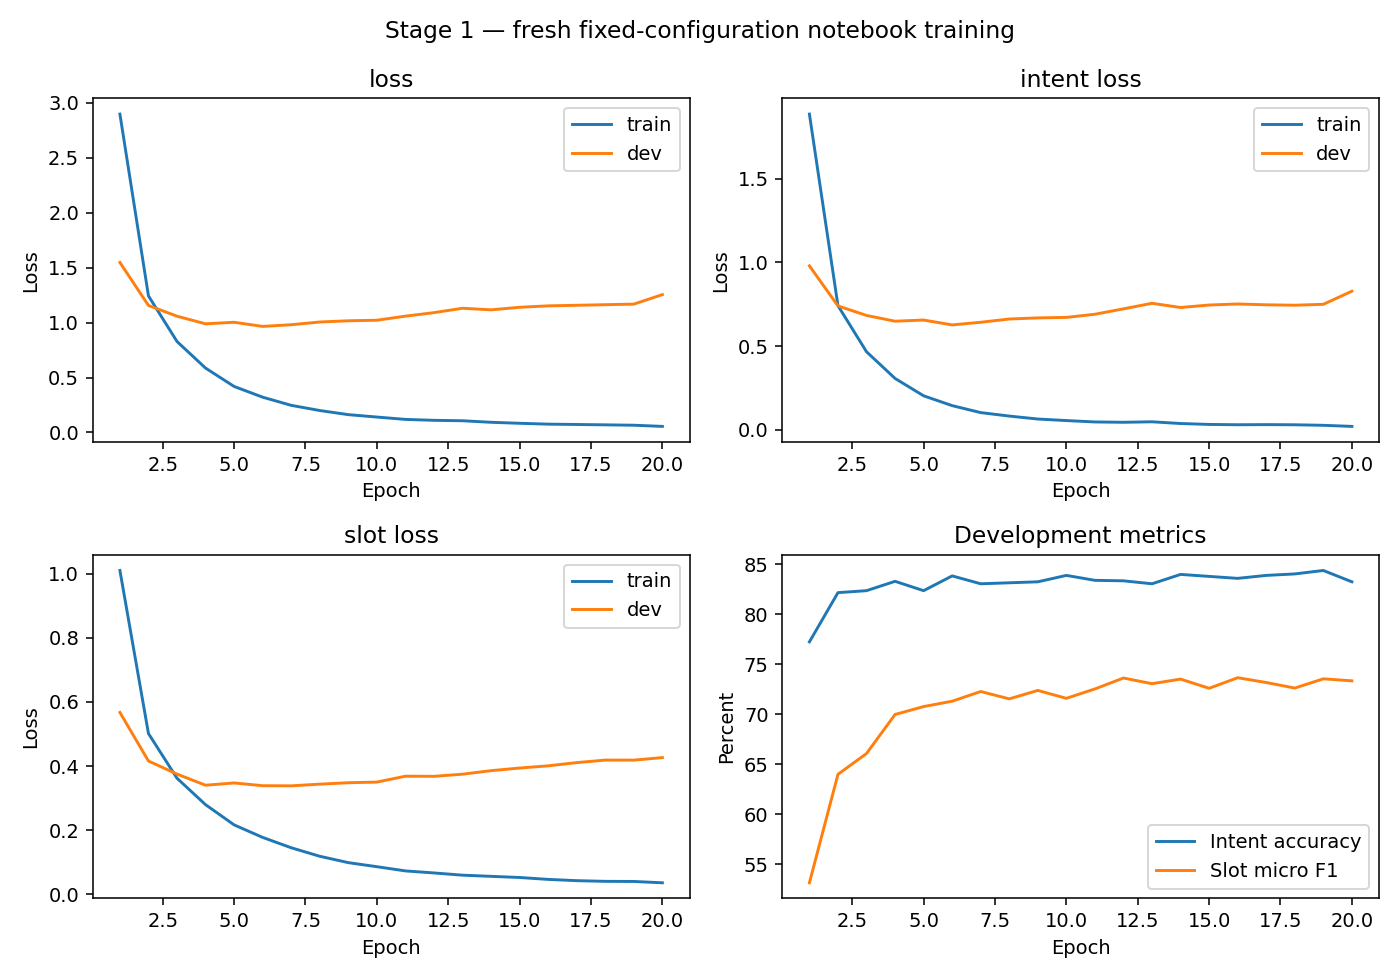

In [21]:
stage1_training = nb_train_stage('stage1', prepared, mappings, char_to_id, STAGE1_CONFIG,
    RUNTIME, DEVICE, RUN_ROOT / 'stage1', DATA_SHA256, CODE_SHA256)
display(Image(filename=str(RUN_ROOT / 'stage1/learning_curves.png')))


## Reload, verify and freeze Stage 1; final evaluation

A new Python process receives ordinary Python generated from the visible definitions in this notebook, independently refits train mappings and reproduces all ordered development predictions from the newly saved checkpoint. The parent also reloads a fresh model, verifies development again, persists a freeze, and then performs one complete test pass. Model weights and checkpoint bytes must remain unchanged. Test results are reporting-only.

In [22]:
stage1_reload = nb_run_fresh_verifier(NOTEBOOK_PATH, RUN_ROOT / 'stage1/best.pt', DATASET_PATH, CODE_SHA256, DEVICE,
    timeout=RUN_OPTIONS.get('verification_timeout_seconds', 300))
stage1_final = nb_finalize_stage(RUN_ROOT / 'stage1/best.pt', prepared['dev'], prepared['test'],
    mappings, char_to_id, DEVICE, DATA_SHA256, CODE_SHA256, evaluate_test=RUN_OPTIONS['evaluate_test'])


FRESH_PROCESS_DEVELOPMENT_VERIFIED {"passed": true, "stage": "stage1", "fresh_python_process": true, "verification_pid": 24548, "training_pid": 8204, "python_executable": "C:\\Users\\Admin\\Desktop\\SC4002\\.venv\\Scripts\\python.exe", "verified_at_utc": "2026-10-31T03:16:49.816330+00:00", "ordered_predictions_equal": true, "absolute_score_difference": 0.0, "selection_score": 0.7894657696518492, "epoch": 19, "num_examples": 2033, "metrics": {"intent_accuracy": 0.8435809149040826, "slot_micro_f1": 0.7353506243996157, "slot_tp": 1531, "slot_fp": 621, "slot_fn": 481, "num_examples": 2033, "correct_intents": 1715}, "test_evaluated": false, "checkpoint_sha256": "fcf9a858b1ab2cb0b3813e9b4d008361f245501960906a98bc3f3eebf0c2fc7d", "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e", "code_sha256": "59fa59f987aac1e48727550a5144b511e086611aec7f7fd65b752625c12f7c38"}
stage1: selected epoch 19/20; reloaded development intent=84.36%, slot F1=73.54%; final test intent=8

## Development-only diagnosis and AI collaboration

The following analysis uses this notebook's Stage 1 development predictions and training support counts. OOV groups, intent confusions and missed-slot boundary categories are descriptive associations, not proof of causes. Character features, CRF decoding and predicted-intent context were accepted as bounded hypotheses; more capacity, blanket class weighting and test-driven iteration were not included. The selected settings stay fixed regardless of this reproduction's test scores. Human reasoning/contributions and full genuine chat export remain part of the final collaboration/report work.

In [23]:
stage1_diagnosis = nb_display_diagnosis(splits['train'], splits['dev'],
    read_predictions(RUN_ROOT / 'stage1/dev_predictions.jsonl'), mappings, RUN_ROOT / 'stage1_diagnosis.json')


| Development group | Utterances | Intent accuracy | Slot micro F1 |
| --- | ---: | ---: | ---: |
| contains_oov | 351 | 70.94% | 58.31% |
| no_oov | 1682 | 87.16% | 76.92% |

Development missed-slot categories: {'exact_boundary_wrong_type': 65, 'no_overlap': 185, 'overlap_wrong_type_and_boundary': 48, 'same_type_wrong_boundary': 183}
Development intent confusions: [{'gold_intent': 'general_quirky', 'predicted_intent': 'qa_factoid', 'count': 9}, {'gold_intent': 'qa_factoid', 'predicted_intent': 'general_quirky', 'count': 9}, {'gold_intent': 'recommendation_events', 'predicted_intent': 'news_query', 'count': 6}, {'gold_intent': 'calendar_set', 'predicted_intent': 'calendar_query', 'count': 5}, {'gold_intent': 'general_quirky', 'predicted_intent': 'news_query', 'count': 5}]


## Train and select Stage 2 from random initialization

Stage 2 starts afresh with the configured seed. It uses original training data, a persistent shuffled loader, the same development selection policy and its configured epoch budget (default 20). It does not warm-start from Stage 1 or use gold intent as input. All learned components count toward the cap.

stage2: parameters total=4,939,498; trainable=4,939,498; cap=20,000,000
stage2 epoch 01/20: train_loss=2.490027; dev_loss=1.240157; intent=78.31%; slot_F1=61.48%; mean=69.89%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=14.350/1.062; selected=True
stage2 epoch 02/20: train_loss=0.991097; dev_loss=0.925239; intent=82.39%; slot_F1=71.39%; mean=76.89%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=13.213/0.974; selected=True
stage2 epoch 03/20: train_loss=0.640318; dev_loss=0.839721; intent=83.72%; slot_F1=73.91%; mean=78.81%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=13.350/1.010; selected=True
stage2 epoch 04/20: train_loss=0.439436; dev_loss=0.814524; intent=83.37%; slot_F1=76.46%; mean=79.92%; train=11514/83008 records/tokens; dev=2033/14522; seconds(train/dev)=13.076/1.031; selected=True
stage2 epoch 05/20: train_loss=0.313402; dev_loss=0.807225; intent=84.01%; slot_F1=76.76%; mean=80.39%; train=11514/83008 re

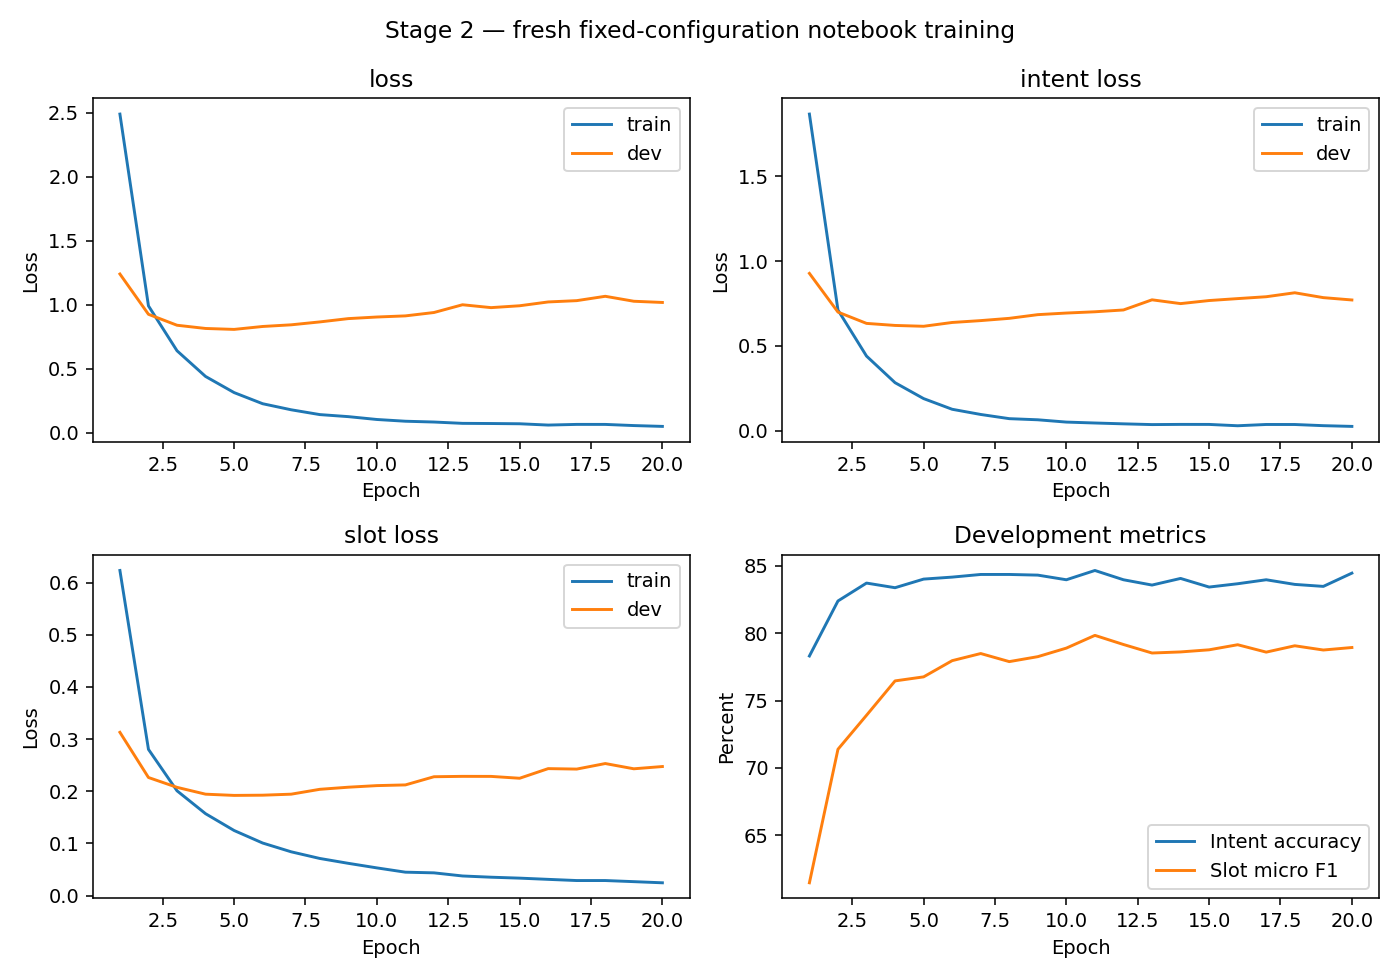

In [24]:
stage2_training = nb_train_stage('stage2', prepared, mappings, char_to_id, STAGE2_CONFIG,
    RUNTIME, DEVICE, RUN_ROOT / 'stage2', DATA_SHA256, CODE_SHA256)
display(Image(filename=str(RUN_ROOT / 'stage2/learning_curves.png')))


## Reload, verify and freeze Stage 2; final evaluation

The same independent reload and freeze-before-test policy applies. No test score changes the selected epoch, architecture or configuration. Preserve and report any regression as part of the result.

In [25]:
stage2_reload = nb_run_fresh_verifier(NOTEBOOK_PATH, RUN_ROOT / 'stage2/best.pt', DATASET_PATH, CODE_SHA256, DEVICE,
    timeout=RUN_OPTIONS.get('verification_timeout_seconds', 300))
stage2_final = nb_finalize_stage(RUN_ROOT / 'stage2/best.pt', prepared['dev'], prepared['test'],
    mappings, char_to_id, DEVICE, DATA_SHA256, CODE_SHA256, evaluate_test=RUN_OPTIONS['evaluate_test'])


FRESH_PROCESS_DEVELOPMENT_VERIFIED {"passed": true, "stage": "stage2", "fresh_python_process": true, "verification_pid": 23592, "training_pid": 8204, "python_executable": "C:\\Users\\Admin\\Desktop\\SC4002\\.venv\\Scripts\\python.exe", "verified_at_utc": "2026-10-31T03:22:20.941639+00:00", "ordered_predictions_equal": true, "absolute_score_difference": 0.0, "selection_score": 0.8224555722174794, "epoch": 11, "num_examples": 2033, "metrics": {"intent_accuracy": 0.8465322183964584, "slot_micro_f1": 0.7983789260385005, "slot_tp": 1576, "slot_fp": 360, "slot_fn": 436, "num_examples": 2033, "correct_intents": 1721}, "test_evaluated": false, "checkpoint_sha256": "060524128cbf3a1ece8e085f604ab3174a8c0453d62d42eca18db76e78f4ed24", "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e", "code_sha256": "59fa59f987aac1e48727550a5144b511e086611aec7f7fd65b752625c12f7c38"}
stage2: selected epoch 11/20; reloaded development intent=84.65%, slot F1=79.84%; final test intent=8

## Generated comparison and genuine remaining errors

Rows come from this run's reloaded checkpoints: four rows in final mode, two development rows in tuning mode. `epochs_trained` is the configured budget; `selected_epoch` is separate. Full-precision scores/counts remain in JSON. Genuine Stage 2 development errors use original labels and predictions; explanations are inferences.

In [26]:
results = nb_build_result_table(stage1_final, stage2_final, RUN_ROOT)
error_cases = nb_show_error_cases(splits['train'], splits['dev'],
    read_predictions(RUN_ROOT / 'stage2/dev_predictions.jsonl'), mappings, RUN_ROOT / 'error_cases.json')


| model_version | split | total_parameters | trainable_parameters | intent_accuracy_percent | slot_micro_f1_percent | epochs_trained | selected_epoch |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Stage-1 system | Validation | 4646571 | 4646571 | 84.36 | 73.54 | 20 | 19 |
| Stage-1 system | Test | 4646571 | 4646571 | 83.96 | 70.47 | 20 | 19 |
| Stage-2 system | Validation | 4939498 | 4939498 | 84.65 | 79.84 | 20 | 11 |
| Stage-2 system | Test | 4939498 | 4939498 | 82.62 | 76.76 | 20 | 11 |

UNROUNDED_METRIC_DELTAS {"dev": {"intent_accuracy": 0.2951303492375823, "slot_micro_f1": 6.302830163888473}, "test": {"intent_accuracy": -1.344989912575656, "slot_micro_f1": 6.294071146245061}}


**Actual remaining development error: record 42**

```json
{
  "record_id": "42",
  "utt": "give me the status on my available memory",
  "gold_intent": "general_quirky",
  "predicted_intent": "calendar_query",
  "gold_slots": [],
  "predicted_slots": [],
  "oov_tokens": [
    "memory"
  ],
  "rare_train_tokens": [],
  "false_negative_pairs": [],
  "false_positive_pairs": [],
  "possible_causes_labelled_as_inferences": [
    "Inference: unfamiliar words lack trained word-specific embeddings; character spelling features may not establish their entity meaning.",
    "Inference: short utterance/context ambiguity and limited examples for this phrasing may contribute; this example alone cannot establish a cause."
  ],
  "possible_future_work": "Investigate targeted training-only support/error patterns and calibration with development data in a separate future study; do not tune using this run's test results."
}
```

**Actual remaining development error: record 67**

```json
{
  "record_id": "67",
  "utt": "i'd like to hear queen's barcelona",
  "gold_intent": "play_music",
  "predicted_intent": "play_music",
  "gold_slots": [
    {
      "slot_type": "artist_name",
      "text": "queen's",
      "start": 17,
      "end": 24
    },
    {
      "slot_type": "song_name",
      "text": "barcelona",
      "start": 25,
      "end": 34
    }
  ],
  "predicted_slots": [
    {
      "slot_type": "artist_name",
      "text": "queen's barcelona",
      "start": 17,
      "end": 34
    }
  ],
  "oov_tokens": [],
  "rare_train_tokens": [
    "queen",
    "barcelona"
  ],
  "false_negative_pairs": [
    {
      "slot_type": "artist_name",
      "text": "queen's",
      "start": 17,
      "end": 24,
      "category": "same_type_wrong_boundary"
    },
    {
      "slot_type": "song_name",
      "text": "barcelona",
      "start": 25,
      "end": 34,
      "category": "overlap_wrong_type_and_boundary"
    }
  ],
  "false_positive_pairs": [
    {
      "slot_type": "artist_name",
      "text": "queen's barcelona",
      "start": 17,
      "end": 34,
      "category": "same_type_wrong_boundary"
    }
  ],
  "possible_causes_labelled_as_inferences": [
    "Inference: the structured decoder still under- or over-extends this entity; valid BIO transitions do not guarantee the correct semantic boundary."
  ],
  "possible_future_work": "Investigate targeted training-only support/error patterns and calibration with development data in a separate future study; do not tune using this run's test results."
}
```

**Actual remaining development error: record 24**

```json
{
  "record_id": "24",
  "utt": "make a room darker",
  "gold_intent": "iot_hue_lightdim",
  "predicted_intent": "iot_hue_lightup",
  "gold_slots": [
    {
      "slot_type": "house_place",
      "text": "room",
      "start": 7,
      "end": 11
    }
  ],
  "predicted_slots": [
    {
      "slot_type": "house_place",
      "text": "room",
      "start": 7,
      "end": 11
    }
  ],
  "oov_tokens": [],
  "rare_train_tokens": [
    "darker"
  ],
  "false_negative_pairs": [],
  "false_positive_pairs": [],
  "possible_causes_labelled_as_inferences": [
    "Inference: short utterance/context ambiguity and limited examples for this phrasing may contribute; this example alone cannot establish a cause."
  ],
  "possible_future_work": "Investigate targeted training-only support/error patterns and calibration with development data in a separate future study; do not tune using this run's test results."
}
```

**Actual remaining development error: record 30**

```json
{
  "record_id": "30",
  "utt": "cleaning is good dust is so bad do now your magic clean my carpet",
  "gold_intent": "iot_cleaning",
  "predicted_intent": "calendar_remove",
  "gold_slots": [
    {
      "slot_type": "house_place",
      "text": "carpet",
      "start": 59,
      "end": 65
    }
  ],
  "predicted_slots": [],
  "oov_tokens": [],
  "rare_train_tokens": [
    "dust"
  ],
  "false_negative_pairs": [
    {
      "slot_type": "house_place",
      "text": "carpet",
      "start": 59,
      "end": 65,
      "category": "no_overlap"
    }
  ],
  "false_positive_pairs": [],
  "possible_causes_labelled_as_inferences": [
    "Inference: short utterance/context ambiguity and limited examples for this phrasing may contribute; this example alone cannot establish a cause."
  ],
  "possible_future_work": "Investigate targeted training-only support/error patterns and calibration with development data in a separate future study; do not tune using this run's test results."
}
```

## Limitations and completion checks

This is a single-seed reproduction of a bounded search, not a statistical significance study or global optimum. Valid BIO paths do not guarantee correct entity boundaries or types. Character features cannot resolve all unfamiliar entity meanings, and intent context can propagate intent mistakes. Training/development loss divergence and genuine errors should guide any separately authorized future study using training/development evidence.

Scoring uses exact typed character-span occurrences; parity with an unavailable lecturer scorer is unverified. Full workflow time includes train, development scoring, checkpoint writes and logs, excluding setup, plotting, independent verification and final evaluation. Per-evaluation timer boundaries differ between stage algorithms and are not comparable microbenchmarks. Historical v1 scores/checkpoint selections are not current results. The final report must use actual newly executed outputs, and the submission must preserve them.

In [27]:
for stage, summary, settings in [('stage1', stage1_final, STAGE1_CONFIG), ('stage2', stage2_final, STAGE2_CONFIG)]:
    assert summary['status'] == 'complete' and summary['epochs_trained'] == settings['training']['max_epochs']
    assert summary['test_model_evaluations'] == int(RUN_OPTIONS['evaluate_test'])
    assert summary['model_weights_unchanged'] and summary['checkpoint_bytes_unchanged']
    assert summary['training_and_tuning_closed'] == RUN_OPTIONS['evaluate_test']
    assert summary['fresh_process_reload']['ordered_predictions_equal']
    assert summary['fresh_process_reload']['absolute_score_difference'] == 0
    assert summary['dev']['num_examples'] == 2033
    if RUN_OPTIONS['evaluate_test']:
        assert summary['test']['num_examples'] == 2974
assert len(results['rows']) == (4 if RUN_OPTIONS['evaluate_test'] else 2)
completion = {'schema_version': 1, 'status': 'complete', 'completed': True,
    'evaluator_version': EVALUATOR_VERSION, 'dataset_identity': dataset_identity,
    'mode': 'final' if RUN_OPTIONS['evaluate_test'] else 'development_only',
    'run_configuration': 'run_configuration.json',
    'configuration_sha256': configuration_snapshot['configuration_sha256'],
    'execution_id': runtime_evidence['execution_id'], 'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': ENGLISH_PATH, 'dataset_sha256': DATA_SHA256,
    'implementation_sha256': CODE_SHA256, 'code_sha256': CODE_SHA256,
    'stages': {stage: {'directory': stage, 'summary': stage + '/final_summary.json'} for stage in ['stage1', 'stage2']},
    'total_epochs_trained': stage1_final['epochs_trained'] + stage2_final['epochs_trained'],
    'results': 'results.json', 'error_cases': 'error_cases.json',
    'new_model_test_evaluations': {'stage1': int(RUN_OPTIONS['evaluate_test']), 'stage2': int(RUN_OPTIONS['evaluate_test'])},
    'group_details': 'Pending at user request',
    'scope': 'Fresh configured notebook training; no historical checkpoint or score loaded.'}
nb_support_write_json(RUN_ROOT / 'completion.json', completion)
print('PHASE7_COMPLETION_JSON:', json.dumps(completion, ensure_ascii=False))


PHASE7_COMPLETION_JSON: {"schema_version": 1, "status": "complete", "completed": true, "evaluator_version": "exact_character_span_v2", "dataset_identity": {"evaluator_version": "exact_character_span_v2", "dataset_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e", "source_url": "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz", "archive_member": "1.0/data/en-US.jsonl", "counts": {"train": 11514, "dev": 2033, "test": 2974}, "split_id_sha256": {"train": "b8165414cd52ae41e997e053252c4467deb4bed4a062600a25b4efb1b8516b18", "dev": "c639005344d7d0a2d93b919a2f17e4e3e8ba1e0fe1cd4a8462ea85b7762e6170", "test": "33aa94f6b04c58b015554af6faa1fd8b40614dc0442ac2ab8e3704ff41fa3bd8"}, "split_content_sha256": {"train": "ba104c94781f77633762bb262ab50926143477db4a37a778b9ee3f299d73227f", "dev": "7f1b358b5e5246a4be6b0557ef53cc763fcb04371ede3463959d91dac9e0fb8f", "test": "b3a1a6c8370a4db616ebc916e68d3d3c36f71ea139a53cdfe94facdd48067dda"}, "identi